# Integración de datos externos y análisis exploratorio con un proceso ETL
## Rendimiento de los cultivos del Valle del Cauca y su relación con la temperatura - fuente externa de temperatura el IDEAM

**Asignatura:** Ciencia de Datos con Python (IGS38) · Universidad Santiago de Cali

**Caso de estudio:** Analítica de datos abiertos de Colombia con datos.gov.co

**Parte 2:** Integración de datos externos y análisis exploratorio (RA3 y RA4)

**Autor:** Juan David Muñoz Sotelo

Este proyecto continúa la Parte 1. Allí se limpiaron **siete conjuntos agrícolas** del Valle del Cauca y se guardó `data/procesados/cultivos_limpio.csv`. Aquí **no se vuelve a limpiar la agricultura**: se lee ese archivo ya procesado y se **cruza con una fuente externa, la temperatura del aire del IDEAM**, para explorar si el clima se relaciona con el rendimiento.

## Propuesta
**Pregunta.** ¿Cómo ha evolucionado el rendimiento de los principales cultivos del Valle del Cauca a lo largo del tiempo y qué relación existe entre sus variaciones y la temperatura registrada en los municipios donde se producen?

**Hipótesis general (Parte 1).** El aumento de la temperatura se asocia con una disminución del rendimiento agrícola (t/ha). La asociación podría ser más pronunciada en los cultivos transitorios que en los permanentes, por sus ciclos productivos y su exposición al clima.

## El cruce
| | Fuente agrícola (Parte 1) | Fuente externa (IDEAM) |
|---|---|---|
| **Conjunto** | `cultivos_limpio.csv` | Temperatura ambiente del aire, `sbwg-7ju4` |
| **Granularidad** | municipio · año · cultivo · ciclo | estación · sensor · lectura (cada pocos minutos) |
| **Llave** | `id_municipio` (DIVIPOLA) + `anio` | `municipio` (texto) + fecha |

Los dos conjuntos **no comparten llave**: el IDEAM trae el municipio como texto y una lectura por fecha y hora, mientras que la agricultura trae DIVIPOLA y un dato por año. Por eso gran parte del trabajo es **llevar la temperatura a la granularidad municipio-año** y **construir el código DIVIPOLA** a partir del nombre.

## Cómo ejecutar este notebook
1. Instala las librerías (una sola vez): `pip install pandas numpy matplotlib seaborn scipy requests`. **`scipy` es necesaria** para las correlaciones con valor p y las pruebas de hipótesis (Cap. 3 del curso); `seaborn`, para los gráficos estadísticos (Cap. 5).
2. Ejecuta antes la Parte 1: debe existir `data/procesados/cultivos_limpio.csv`.
3. Ubica `Estudio_de_caso_Parte2.ipynb` junto a la carpeta `data/`.
4. Necesitas conexión a internet la **primera vez**: la temperatura se consulta a la API de datos.gov.co y se guarda en `data/temperatura_valle_agregada.csv`. Las ejecuciones siguientes usan ese archivo (`USAR_CACHE = True`) y no vuelven a consultar el portal.
5. Al final se guardan `temperatura_municipio_anio.csv` y `cultivos_temperatura.csv` en `data/procesados/`; este último es la **entrada de la Parte 3**.

| | |
|---|---|
| Equipo | Juan David Muñoz Sotelo |
| Pregunta del proyecto | ¿Cómo ha evolucionado el rendimiento de los principales cultivos del Valle del Cauca a lo largo del tiempo y qué relación existe entre sus variaciones y la temperatura registrada en los municipios donde se producen? |


## ¿Por qué hay que armonizar estas fuentes?

Integrar no es solo hacer un `merge`. Estos son los problemas reales de este cruce:

- **Granularidad distinta.** Una estación del IDEAM genera cientos de miles de lecturas; la agricultura tiene **un dato por municipio y año**. Hay que agregar antes de unir.
- **Volumen.** El conjunto de temperatura tiene ~93,5 millones de filas a nivel nacional. Se **filtra y agrega en el servidor** (SoQL) para traer solo lo necesario.
- **Sin llave común.** El IDEAM no trae DIVIPOLA, solo el nombre del municipio (`GUADALAJARA DE BUGA` frente a `Buga`, tildes, mayúsculas). Hay que **construir la llave** con un catálogo.
- **Sensores que fallan.** Lecturas de 0 °C, valores imposibles y meses con muy pocas lecturas pueden sesgar un promedio anual.
- **Sensores distintos.** Temperatura media, máxima y mínima conviven en la misma tabla y no se pueden promediar entre sí.
- **Cobertura desigual.** No todos los municipios tienen estación y las estaciones no operan todos los años. Un cruce nunca será del 100 %: hay que **medirlo y explicarlo**.

## ETL y ELT

Se mantiene el proceso **ETL** (*Extract, Transform, Load*) de la Parte 1:

| Etapa | Qué hacemos en este notebook |
|---|---|
| **E — Extraer** | Leer `cultivos_limpio.csv` (ya procesado) y consultar la temperatura del IDEAM a la API de datos.gov.co. Todo se lee como texto. |
| **T — Transformar** | Limpiar la temperatura (copias, unidades, rangos, sensores, nombres), construir el DIVIPOLA, llevarla a municipio-año e **integrar** con `merge`. |
| **L — Cargar** | Guardar la temperatura limpia y la tabla integrada en CSV, lista para la Parte 3. |

### ¿En qué se diferencia de ELT?
En **ETL** los datos se transforman **antes** de guardarse; en **ELT** se cargan en bruto y se transforman dentro del destino.

| | ETL | ELT |
|---|---|---|
| Orden | Extraer → Transformar → Cargar | Extraer → Cargar → Transformar |
| Dónde se transforma | En un proceso intermedio (aquí, `pandas`) | Dentro del destino (almacén o *data lake*) |
| Qué se guarda | Solo datos limpios | Datos en bruto + transformaciones |

**En este caso (enfoque mixto).** Los 93,5 millones de lecturas no caben cómodamente en memoria, así que la **primera reducción ocurre en el servidor** del portal (filtro por departamento y periodo, descarte de lecturas imposibles y promedio mensual por estación): esa parte se parece a un ELT, porque el cálculo pesado lo hace el destino. La **limpieza fina, la construcción de la llave, la integración y el análisis** se hacen en `pandas`, como en un ETL clásico.

## Ruta
1. **Extraer**: `cultivos_limpio.csv` y temperatura (API o caché).
2. **Transformar**
   - Exploración inicial (diagnóstico) de la temperatura.
   - T1. Eliminar lo que no sirve (copias, columnas vacías).
   - T2. Corregir (espacios, marcadores, mayúsculas, códigos).
   - T3. Estructurar (tipos, unidades, rangos, sensores, llaves repetidas, municipio → DIVIPOLA, agregación municipio-año, anomalías).
   - T4. Completar (qué se imputa y qué no).
3. **Integrar** con `merge` y medir el cruce.
4. **Análisis exploratorio** sobre el conjunto integrado.
5. **Hipótesis** para la Parte 3.
6. **Cargar**, **validar**, **reporte de calidad** y **linaje de datos**.

## Fuentes de datos externa

| Conjunto | ID | Archivo | Rol en el análisis | Enlace |
|---|---|---|---|---|
| Cultivos del Valle del Cauca (7 conjuntos de la Parte 1, ya limpios) | varios | `data/procesados/cultivos_limpio.csv` | **Conjunto principal.** Rendimiento (t/ha), superficie y producción | Ver Parte 1 |
| Temperatura ambiente del aire | `sbwg-7ju4` | `data/temperatura_valle_agregada.csv` (caché de la API) | **Fuente externa explicativa.** Clima por estación | [Ver](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Temperatura-Ambiente-del-Aire/sbwg-7ju4/data_preview) |

**Consulta a la API.** La consulta base filtra solo el Valle del Cauca (el resto de departamentos se ignora):

```
SELECT ... WHERE upper(departamento) LIKE '%VALLE DEL CAUCA%'
```

Se usa el *endpoint* SODA (`/resource/sbwg-7ju4.csv`) con parámetros `$select`, `$where`, `$group`, `$order`, `$limit` y `$offset` (SoQL), que permite **agregar en el servidor** y paginar sin necesidad de autenticación.

### Campos del conjunto de temperatura

| Campo | Descripción |
|---|---|
| `codigoestacion`, `nombreestacion` | Identificador y nombre de la estación del IDEAM |
| `codigosensor`, `descripcionsensor` | Sensor y qué mide (temperatura media, máxima, mínima...) |
| `fechaobservacion` | Fecha y hora de la lectura |
| `valorobservado`, `unidadmedida` | Valor medido y su unidad |
| `departamento`, `municipio`, `zonahidrografica` | Ubicación administrativa e hidrográfica |
| `latitud`, `longitud` | Coordenadas de la estación |

### Columnas nuevas de este notebook

| Columna | Descripción | Tipo | Unidad |
|---|---|---|---|
| `t_media` | Temperatura media anual del municipio (promedio de sus 12 medias mensuales) | `float` | °C |
| `t_min_abs`, `t_max_abs` | Lectura mínima y máxima registrada en el año | `float` | °C |
| `amplitud_termica` | Mes más cálido − mes más frío (medias mensuales) | `float` | °C |
| `n_meses`, `n_estaciones`, `n_lecturas` | Cobertura: meses con dato, estaciones y lecturas del año | `int` | — |
| `t_media_hist`, `clima_municipio` | Temperatura histórica del municipio y su clase (Frío, Templado, Cálido) | `float`, `str` | °C |
| `t_anomalia`, `amplitud_anomalia` | Valor del año menos el promedio histórico del municipio | `float` | °C |
| `t_anomalia_prev` | `t_anomalia` del año anterior (rezago de 1 año) | `float` | °C |
| `rend_relativo` | `rendimiento_t_ha / mediana_cultivo`: permite comparar cultivos con escalas distintas | `float` | razón |
| `rend_anomalia` | `rend_relativo` menos el promedio de su municipio-cultivo-ciclo | `float` | razón |
| `tiene_temperatura`, `en_base_analisis` | Marcas de cruce y de inclusión en el análisis | `bool` | — |
| `causa_sin_temperatura` | Motivo por el que un registro no cruzó | `str` | — |

## Mapa del notebook frente a la plantilla de la Entrega 2

Todo el contenido del cuaderno original se conserva; solo se reubicó bajo los apartados de la plantilla y se agregaron las piezas que la plantilla pide y no existían.

| Apartado de la plantilla | Dónde está en este cuaderno | Antes se llamaba |
|---|---|---|
| **0.** Configuración de fuentes | Constantes y configuración + diccionario `FUENTES` | Constantes y configuración |
| **1.** Conjunto limpio de la Entrega 1 | Lectura de `cultivos_limpio.csv` | 1. EXTRAER (cultivos) |
| **2.** Funciones de armonización | Funciones auxiliares, `a_divipola` con `assert`, catálogo DIVIPOLA | Funciones auxiliares, catálogo |
| **3.** Obtención de fuentes externas | 3.1 contexto (pendiente) · 3.2 temperatura IDEAM por API con caché | 1.2 Temperatura |
| **4.** Armonización de formatos | Tabla de decisiones + limpieza T0–T4 | 2. TRANSFORMAR |
| **5.** Integración | 5.1 *reindexing* · 5.2 `merge` y causas · 5.3 linaje · 5.4 variables derivadas | 3. INTEGRAR y 7.4 Linaje |
| **6.** Análisis exploratorio | 6.1 descriptivos · 6.2 distribuciones · 6.3 territorio · 6.4 correlaciones · 6.5 estacionalidad y tendencia | 4. Análisis exploratorio |
| **7.** Hipótesis para la Parte 3 | H1–H5 con H0/Ha + tabla en formato de plantilla | 4.6 Hallazgos |
| **8.** Guardado, limitaciones y chequeo | Cargar, validación, reporte de calidad, limitaciones, lista de chequeo | 5. CARGAR, 6. Validación, 7. Reporte |

### Verificación de librerías
Antes de ejecutar el notebook comprobar que las librerías necesarias estén instaladasen el `requirements.txt estan las requeridas. Después de instalar.

In [23]:
import sys
import subprocess
import importlib

# nombre para importar -> nombre del paquete en pip
LIBRERIAS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scipy": "scipy",
    "requests": "requests",
    "IPython": "ipython"
}

print(f"Python del kernel: {sys.executable}\n")
instaladas_ahora, fallidas = [], []

for modulo, paquete in LIBRERIAS.items():
    try:
        m = importlib.import_module(modulo)
        print(f"{modulo:<12} ya estaba instalada (versión {getattr(m, '__version__', '?')})")
    except ImportError:
        print(f"{modulo:<12} no está instalada, instalando...")
        resultado = subprocess.run([sys.executable, "-m", "pip", "install", paquete],
                                   capture_output=True, text=True)
        if resultado.returncode == 0:
            print(f"{modulo:<12} instalada correctamente")
            instaladas_ahora.append(modulo)
        else:
            print(f"{modulo:<12} falló la instalación:")
            print(resultado.stderr[-400:])
            fallidas.append(modulo)

print()
if fallidas:
    print("No se pudo instalar:", ", ".join(fallidas), "· revisa tu conexión a internet o tus permisos.")
elif instaladas_ahora:
    print("Se instalaron:", ", ".join(instaladas_ahora))
    print("IMPORTANTE: reinicia el kernel (Kernel > Restart) y ejecuta el notebook desde la primera celda.")
else:
    print("Todo estaba instalado. Puedes ejecutar el notebook.")

Python del kernel: c:\Users\juand\Downloads\Ciencia de datos\.venv\Scripts\python.exe

numpy        ya estaba instalada (versión 2.5.4)
pandas       ya estaba instalada (versión 3.1.1)
matplotlib   ya estaba instalada (versión 3.11.2)
seaborn      ya estaba instalada (versión 0.13.2)
scipy        ya estaba instalada (versión 1.18.1)
requests     ya estaba instalada (versión 2.34.2)
IPython      ya estaba instalada (versión 9.18.1)

Todo estaba instalado. Puedes ejecutar el notebook.


## Constantes y configuración

Se definen una sola vez las rutas, los parámetros de la consulta y las **reglas de limpieza**. Si cambia una regla (el rango de temperatura plausible, los meses mínimos para considerar un año...) solo se configura aquí.

In [62]:
import io
import json
import math
import os
import re
import time
import difflib
import unicodedata
from collections import Counter
from datetime import date, datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import seaborn as sns
from IPython.display import display
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

FECHA_EJECUCION = datetime.now().strftime("%Y-%m-%d")

# ----- Rutas
CARPETA_DATOS = "data"
CARPETA_TEMPERATURA = f"{CARPETA_DATOS}/temperatura"
CARPETA_SALIDA = "data/procesados"
os.makedirs(CARPETA_SALIDA, exist_ok=True)
ARCHIVO_CULTIVOS = "../laboratorio_1/data/procesados/cultivos_limpio.csv"          # salida de la Parte 1
ARCHIVO_TEMP_CACHE   = f"{CARPETA_TEMPERATURA}/temperatura_valle_agregada.csv"  # caché de la API
ARCHIVO_TEMP_META    = f"{CARPETA_TEMPERATURA}/temperatura_valle_meta.json"
RUTA_TEMP_CSV_MANUAL = f"{CARPETA_TEMPERATURA}/temperatura.csv"                 # plan B: CSV descargado a mano
CARPETA_PARCIALES    = f"{CARPETA_DATOS}/temp_parciales"                  # un archivo por año: permite reanudar
ARCHIVO_TEMP_MES     = f"{CARPETA_SALIDA}/temperatura_municipio_mes.csv"
ARCHIVO_TEMP_ANIO    = f"{CARPETA_SALIDA}/temperatura_municipio_anio.csv"
ARCHIVO_INTEGRADO    = f"{CARPETA_SALIDA}/cultivos_temperatura.csv"       # entrada de la Parte 3

# Crear las carpetas necesarias
os.makedirs(CARPETA_TEMPERATURA, exist_ok=True)
os.makedirs(CARPETA_PARCIALES, exist_ok=True)
os.makedirs(CARPETA_SALIDA, exist_ok=True)

# ----- API de datos.gov.co (Socrata / SoQL)
ID_TEMP = "sbwg-7ju4"
URL_RECURSO = f"https://www.datos.gov.co/resource/{ID_TEMP}.csv"
URL_VISTA = f"https://www.datos.gov.co/api/views/{ID_TEMP}.json"
DEPARTAMENTO = "VALLE DEL CAUCA"
APP_TOKEN = os.getenv("SOCRATA_APP_TOKEN")      # opcional
USAR_CACHE = True                               # False fuerza una nueva consulta a la API
TIMEOUT_SEGUNDOS = 120                          # espera máxima por consulta al portal

# ----- Parámetros de limpieza
ANIO_MIN, ANIO_MAX = 2000, 2023                 # mismo periodo que la Parte 1
TEMP_MIN_EXCLUSIVO, TEMP_MAX = 0.0, 45.0        # 0 °C = falla de sensor; > 45 °C imposible en el Valle
SENSOR_TEXTO = "TEMP"                           # el sensor debe mencionar "temperatura"
TIPOS_SENSOR_USADOS = {"Media/Instantánea"}     # las máximas y mínimas miden otra cosa
MIN_LECTURAS_MES = 30                           # mes con menos lecturas no es representativo
MIN_MESES_ANIO = 6                              # un año necesita al menos 6 meses con dato
MIN_ANIOS_ANOMALIA = 5                          # años mínimos para calcular un promedio histórico
UMBRAL_FRIO_CALIDO = 0.5                        # °C de anomalía para llamar "cálido" o "frío" a un año
BBOX_VALLE = {"lat": (2.5, 5.5), "lon": (-78.5, -75.0)}   # caja amplia alrededor del Valle
CUTOFF_NOMBRE_APROX = 0.88                      # similitud mínima para aceptar un nombre aproximado
MARCADORES_FALTANTE = {"", "SIN DATO", "S/D", "N/A", "NA", "NULL", "NONE", "-", "SIN INFORMACION", "NO REPORTA"}

# Alias de municipios que el IDEAM escribe distinto al DANE / Gobernación (clave y valor sin tildes)
ALIAS_MUNICIPIOS = {
    "GUADALAJARA DE BUGA": "BUGA",
    "SANTIAGO DE CALI": "CALI",
    "DISTRITO DE BUENAVENTURA": "BUENAVENTURA",
    "SAN JUAN BAUTISTA DE GUACARI": "GUACARI",
}

LLAVE_CRUCE = ["id_municipio", "anio"]
LLAVE_CULTIVO = ["anio", "id_municipio", "id_cultivo", "ciclo"]

# Bitácoras para el reporte de calidad
LOG_ETAPAS, CAMBIOS = [], []
print("Listo · pandas", pd.__version__)

Listo · pandas 3.1.1


In [63]:
from pathlib import Path

# Carpetas reales de este proyecto
RAW, PROCESSED, EXTERNOS = Path(CARPETA_PARCIALES), Path(CARPETA_SALIDA), Path(CARPETA_DATOS)

---
# 0. Configuración de fuentes (*McKinney 3.1 — diccionarios*)

Una entrada por fuente. **Nivel excelente:** dos o más fuentes externas, al menos una de contexto o denominador (población, IPM/NBI, TerriData) y una explicativa. Hoy hay una explicativa (IDEAM); la de contexto está pendiente (ver 3.1).

In [64]:
FUENTES = {
    "principal": {"nombre": "Cultivos del Valle del Cauca (7 conjuntos, ya limpios en la Parte 1)",
                  "entidad": "Gobernación del Valle del Cauca", "rol": "Principal",
                  "acceso": "datos.gov.co (Parte 1) -> archivo procesado", "ruta": ARCHIVO_CULTIVOS},
    "contexto": {"nombre": "Pendiente: población DANE / TerriData / IPM-NBI (no incorporada)",
                 "entidad": "-", "rol": "Contexto (denominador)", "acceso": "Sin incorporar (ver 3.1)", "ruta": None},
    "explicativa": {"nombre": f"Temperatura ambiente del aire ({ID_TEMP})", "entidad": "IDEAM",
                    "rol": "Explicativa", "acceso": "API Socrata (SoQL, agregada en el servidor) + caché CSV",
                    "ruta": ARCHIVO_TEMP_CACHE},
}
pd.DataFrame(FUENTES).T

,nombre,entidad,rol,acceso,ruta
principal,"Cultivos del Valle del Cauca (7 conjuntos, ya limpios en la Parte 1)",Gobernación del Valle del Cauca,Principal,datos.gov.co (Parte 1) -> archivo procesado,../laboratorio_1/data/procesados/cultivos_limpio.csv
contexto,Pendiente: población DANE / TerriData / IPM-NBI (no incorporada),-,Contexto (denominador),Sin incorporar (ver 3.1),NaN
explicativa,Temperatura ambiente del aire (sbwg-7ju4),IDEAM,Explicativa,"API Socrata (SoQL, agregada en el servidor) + caché CSV",data/temperatura/temperatura_valle_agregada.csv


---
# 1. Conjunto limpio de la Entrega 1 (ETL: Extraer — cultivos)

## 1.1 Cultivos: leer el archivo ya procesado en la Parte 1
`cultivos_limpio.csv` ya pasó por limpieza, validación y reporte de calidad, así que **solo se lee**. Se usa `dtype` de texto para `id_municipio` e `id_cultivo` y no perder los ceros de los códigos.

In [65]:
if not os.path.exists(ARCHIVO_CULTIVOS):
    raise FileNotFoundError(f"Falta {ARCHIVO_CULTIVOS}: ejecuta primero la Parte 1.")

cultivos = pd.read_csv(ARCHIVO_CULTIVOS, dtype={"id_municipio": str, "id_cultivo": str})
cultivos["id_municipio"] = cultivos["id_municipio"].str.zfill(5)

REQUERIDAS_CULT = ["anio", "id_municipio", "municipio", "subregion", "grupo", "id_cultivo", "cultivo", "ciclo",
                   "rendimiento_t_ha", "hectareas_sembradas", "mediana_cultivo", "tiene_rendimiento", "es_cero"]
faltan = [c for c in REQUERIDAS_CULT if c not in cultivos.columns]
assert not faltan, f"Faltan columnas en cultivos_limpio.csv: {faltan}"
assert cultivos["id_municipio"].str.fullmatch(r"76\d{3}").all(), "DIVIPOLA inválido en cultivos_limpio.csv"
assert not cultivos.duplicated(LLAVE_CULTIVO).any(), "Llaves repetidas en cultivos_limpio.csv"

print(f"cultivos_limpio.csv: {cultivos.shape[0]:,} filas · {cultivos.shape[1]} columnas · "
      f"{cultivos['id_municipio'].nunique()} municipios · años {cultivos['anio'].min()}-{cultivos['anio'].max()}")
display(cultivos.head())
cultivos.groupby("grupo").agg(filas=("anio", "size"), municipios=("id_municipio", "nunique"),
                              cultivos=("id_cultivo", "nunique"), anio_min=("anio", "min"), anio_max=("anio", "max"))

cultivos_limpio.csv: 31,554 filas · 20 columnas · 42 municipios · años 2000-2023


,anio,id_municipio,municipio,subregion,grupo,tipo_cultivo,id_cultivo,cultivo,ciclo,rendimiento_t_ha,hectareas_sembradas,hectareas_cosechadas,produccion_toneladas,produccion_complementaria_t,fuentes_produccion,produccion_conflicto,mediana_cultivo,tiene_rendimiento,es_cero,alerta_consistencia
0,2000,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,4.0,4.0,40.0,40.0,frutales,False,9.22,True,False,False
1,2001,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,3.9,3.9,39.0,39.0,frutales,False,9.22,True,False,False
2,2002,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,6.4,3.9,39.0,39.0,frutales,False,9.22,True,False,False
3,2003,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,9.0,6.5,65.0,65.0,frutales,False,9.22,True,False,False
4,2004,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,9.0,6.5,65.0,65.0,frutales,False,9.22,True,False,False


,filas,municipios,cultivos,anio_min,anio_max
grupo,,,,,
Permanente,15238,42,61,2000,2023
Solo producción,224,23,29,2000,2020
Transitorio,16092,42,55,2000,2022


In [66]:
principal = cultivos          # nombre que usa la plantilla para el conjunto principal
principal.head()

,anio,id_municipio,municipio,subregion,grupo,tipo_cultivo,id_cultivo,cultivo,ciclo,rendimiento_t_ha,hectareas_sembradas,hectareas_cosechadas,produccion_toneladas,produccion_complementaria_t,fuentes_produccion,produccion_conflicto,mediana_cultivo,tiene_rendimiento,es_cero,alerta_consistencia
0,2000,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,4.0,4.0,40.0,40.0,frutales,False,9.22,True,False,False
1,2001,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,3.9,3.9,39.0,39.0,frutales,False,9.22,True,False,False
2,2002,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,6.4,3.9,39.0,39.0,frutales,False,9.22,True,False,False
3,2003,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,9.0,6.5,65.0,65.0,frutales,False,9.22,True,False,False
4,2004,76036,Andalucia,Centro,Permanente,frutales,2040202,Aguacate,Anual,10.0,9.0,6.5,65.0,65.0,frutales,False,9.22,True,False,False


---
# 2. Funciones de armonización (*McKinney 3.2 — funciones*)

Una función por llave, probada con `assert` antes de usarla. Las funciones del cuaderno (`norm_nombre`, `a_numero`, `consultar_socrata`, `correl`…) siguen abajo; se suman `a_divipola` y `buscar_columna` de la plantilla con sus pruebas.

## Funciones auxiliares
- `normalizar_columnas`, `a_numero`, `marcar_nan`, `n_distintos`, `registrar`, `anotar`: las mismas de la Parte 1.
- `norm_nombre`: nombre en mayúsculas, **sin tildes ni signos** (incluida la Ñ), para comparar municipios.
- `consultar_socrata`: consulta paginada a la API, con reintentos si el portal está saturado.
- `correl`: tamaño de muestra, correlación de Pearson y de Spearman (con valor p; si no hay `scipy`, Spearman se calcula sobre los rangos y el valor p es aproximado).
- `fuerza` y `pct_atipicos`: lectura verbal de una correlación y porcentaje de atípicos con la regla del boxplot (1,5·IQR).

In [67]:
def normalizar_columnas(df):
    def limpiar(c):
        c = unicodedata.normalize("NFKD", str(c)).encode("ascii", "ignore").decode()
        return re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_")
    df = df.copy()
    df.columns = [limpiar(c) for c in df.columns]
    return df

def norm_nombre(x):
    if pd.isna(x):
        return x
    t = unicodedata.normalize("NFKD", str(x)).encode("ascii", "ignore").decode().upper()
    t = re.sub(r"[^A-Z0-9 ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def es_miles(s):
    return s.str.fullmatch(r"-?\d{1,3}(\.\d{3})+(,\d+)?").fillna(False).astype(bool)

def a_numero(serie, formato="es"):
    s = serie.astype("string").str.replace(r"\s+", "", regex=True)
    if formato == "en":
        s = s.str.replace(",", "", regex=False)
    else:
        con_miles = es_miles(s)
        s = s.mask(con_miles, s.str.replace(".", "", regex=False))
        s = s.str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce").astype("float64")

def marcar_nan(s):
    return s.mask(s.str.strip().str.upper().isin(MARCADORES_FALTANTE))

def n_distintos(antes, despues):
    ambos_nulos = antes.isna() & despues.isna()
    return int(((antes != despues) & ~ambos_nulos).sum())

def registrar(etapa, antes, despues, decision):
    LOG_ETAPAS.append({"etapa": etapa, "filas_antes": int(antes), "filas_despues": int(despues), "decision": decision})

def anotar(etapa, operacion, tipo, cantidad, detalle=""):
    CAMBIOS.append({"etapa": etapa, "operacion": operacion, "tipo": tipo, "cantidad": int(cantidad), "detalle": detalle})

def consultar_socrata(params, pagina=50_000, max_paginas=400, timeout=None, reintentos=2):
    # Consulta paginada (SoQL). Devuelve todo como texto. Reintenta ante timeouts y errores temporales del portal.
    timeout = timeout or TIMEOUT_SEGUNDOS
    cabeceras = {"X-App-Token": APP_TOKEN} if APP_TOKEN else {}
    partes, offset = [], 0
    for _ in range(max_paginas):
        p = dict(params, **{"$limit": pagina, "$offset": offset})
        ultimo = ""
        for intento in range(reintentos):
            try:
                r = requests.get(URL_RECURSO, params=p, headers=cabeceras, timeout=timeout)
            except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
                ultimo = type(e).__name__
                time.sleep(5 * (intento + 1))
                continue
            if r.status_code == 200:
                break
            if r.status_code in (429, 500, 502, 503, 504):
                ultimo = f"HTTP {r.status_code}"
                time.sleep(5 * (intento + 1))
                continue
            raise ValueError(f"HTTP {r.status_code}: {r.text[:300]}")
        else:
            raise RuntimeError(f"El portal no respondió tras {reintentos} intentos ({ultimo})")
        if not r.text.strip():
            break
        df = pd.read_csv(io.StringIO(r.text), dtype=str)
        partes.append(df)
        if len(df) < pagina:
            break
        offset += pagina
    return pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()

def p_aprox(rho, n):
    # Valor p bilateral aproximado (transformación de Fisher). Solo se usa si no hay scipy.
    if n <= 3 or pd.isna(rho):
        return np.nan
    if abs(rho) >= 1:
        return 0.0
    z = math.atanh(rho) * math.sqrt((n - 3) / 1.06)
    return float(math.erfc(abs(z) / math.sqrt(2)))

def correl(x, y, minimo=10):
    d = pd.concat([x, y], axis=1).dropna()
    d.columns = ["x", "y"]
    n = len(d)
    if n < minimo or d["x"].nunique() < 2 or d["y"].nunique() < 2:
        return {"n": n, "pearson": np.nan, "spearman": np.nan, "p_spearman": np.nan}
    pear = d["x"].corr(d["y"])
    if stats is not None:
        rho, p = stats.spearmanr(d["x"], d["y"])
    else:
        # Spearman = Pearson aplicado a los rangos. (Series.corr(method="spearman") exige scipy, por eso no se usa aquí.)
        rho = d["x"].rank().corr(d["y"].rank())
        p = p_aprox(rho, n)
    return {"n": n, "pearson": round(float(pear), 3), "spearman": round(float(rho), 3), "p_spearman": float(p)}

def fuerza(rho):
    # Lectura verbal del tamaño de una correlación (|rho|)
    if pd.isna(rho):
        return "no calculable"
    a = abs(rho)
    return "prácticamente nula" if a < 0.1 else "débil" if a < 0.3 else "moderada" if a < 0.5 else "fuerte"

def pct_atipicos(s):
    # Regla del boxplot (Cap. 3 y 5): atípico = fuera de [Q1 - 1,5·IQR, Q3 + 1,5·IQR]
    s = s.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return float(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100)

print("Funciones listas")

Funciones listas


In [68]:
def a_divipola(valor):
    if pd.isna(valor):
        return pd.NA
    texto = str(valor).strip()
    if re.fullmatch(r"\d+\.0", texto):
        texto = texto[:-2]
    digitos = re.sub(r"\D", "", texto)
    return digitos.zfill(5) if 1 <= len(digitos) <= 5 else pd.NA

def buscar_columna(columnas, patron, fuente=""):
    encontradas = [c for c in columnas if re.search(patron, str(c), flags=re.IGNORECASE)]
    if not encontradas:
        raise KeyError(f"[{fuente}] ninguna columna cumple {patron!r}: {list(columnas)}")
    return encontradas[0]

# Pruebas de las funciones de armonización
assert a_divipola(5001) == "05001" and a_divipola("76.001") == "76001"
assert a_divipola(76001.0) == "76001" and pd.isna(a_divipola(None))
assert norm_nombre("Bolívar ") == "BOLIVAR" and norm_nombre("Guadalajara de Buga") == "GUADALAJARA DE BUGA"
assert a_numero(pd.Series(["1.234,5"])).iloc[0] == 1234.5 and a_numero(pd.Series(["12.5"]), "en").iloc[0] == 12.5
assert buscar_columna(["Codigo Estacion", "valorObservado"], r"valor") == "valorObservado"

# La llave de la fuente principal ya es DIVIPOLA válido: a_divipola no la cambia
assert (cultivos["id_municipio"].map(a_divipola) == cultivos["id_municipio"]).all()
print("Funciones de armonización: pruebas OK")

Funciones de armonización: pruebas OK


### Catálogo de municipios (DIVIPOLA)
La temperatura del IDEAM solo trae el **nombre** del municipio. El catálogo `id_municipio ↔ municipio` sale del propio archivo de cultivos (la Parte 1 garantizó un solo nombre por código) y servirá para **construir la llave** del cruce.

In [69]:
catalogo = (cultivos[["id_municipio", "municipio", "subregion"]].drop_duplicates()
            .sort_values("id_municipio").reset_index(drop=True))
catalogo["municipio_norm"] = catalogo["municipio"].map(norm_nombre)
assert catalogo["id_municipio"].is_unique, "Un código DIVIPOLA con más de un nombre o subregión"
assert catalogo["municipio_norm"].is_unique, "Dos municipios con el mismo nombre normalizado"
print("Municipios en el catálogo:", len(catalogo))
catalogo.groupby("subregion").size().to_frame("municipios")

Municipios en el catálogo: 42


,municipios
subregion,
Centro,13
Norte,16
Pacifico,1
Sur,12


---
# 3. Obtención de fuentes externas

Desde una **API** o una **base de datos externa**, con caché local (`data/temperatura_valle_agregada.csv` y `data/temp_parciales/`) y manejo de errores con `try/except` (reintentos, plan B con CSV manual).

## 3.1 Fuente de contexto (denominador)

**Estado: pendiente.** El cuaderno no incorpora una fuente de contexto con denominador poblacional. La razón está en 6.3: el rendimiento (t/ha) ya es una razón por superficie, así que dividir por habitantes no tiene sentido agronómico. Para el nivel excelente de la rúbrica RA3 (dos o más fuentes externas, una de contexto) habría que sumar una segunda fuente por API o archivo con la llave DIVIPOLA, por ejemplo proyecciones de población del DANE o TerriData. No se agregó ninguna aquí para no introducir datos que no se hayan verificado.

## 3.2 Fuente explicativa — Temperatura del IDEAM: consulta a la API de datos.gov.co

Cuatro decisiones para no descargar 93,5 millones de filas:

1. **Filtro geográfico y temporal en el servidor**: solo el Valle del Cauca, años 2000-2023.
2. **Descarte de lecturas imposibles en el servidor**: se excluyen `0 °C` (falla del sensor) y valores fuera de `(0, 45]`. Antes se **cuentan** para el reporte de calidad.
3. **Agregación en el servidor**: en lugar de lecturas individuales se pide el **promedio, mínimo, máximo y número de lecturas por estación-sensor-año-mes** (`GROUP BY`). Así la descarga pasa de millones a decenas de miles de filas.
4. **Un año por consulta**: agrupar 24 años de golpe supera el tiempo máximo del portal (*timeout*). Se piden año por año (y mes a mes si un año no responde), con reintentos, y cada año se guarda en `data/temp_parciales/`. Si la descarga se interrumpe, al volver a ejecutar **continúa donde quedó**.

> La primera descarga puede tardar varios minutos. En mi caso 30 min por lo cual le voy a adjuntar el temporal de meses que me dio la API en caso de querer validar que si consulta y descarga solo es que borre la carpeta temp_parciales o borrar ejemplo el csv del año agregado_2023.csv para que el notebook empiece a descargar. Por motivos de comodidad y tiempo los agregó en esta entrega.

In [70]:
def leer_metadatos():
    # Ficha del conjunto en el portal: fecha de corte, entidad y licencia (para el linaje de datos).
    try:
        r = requests.get(URL_VISTA, timeout=60)
        r.raise_for_status()
        j = r.json()
        corte = j.get("rowsUpdatedAt") or j.get("viewLastModified")
        return {"nombre_portal": j.get("name"), "atribucion": j.get("attribution"),
                "licencia": (j.get("license") or {}).get("name") or j.get("licenseId"),
                "fecha_corte_portal": datetime.fromtimestamp(corte).strftime("%Y-%m-%d") if corte else None}
    except Exception as e:
        return {"error_metadatos": str(e)}

COLUMNAS_AGG = ["codigoestacion", "codigosensor", "nombreestacion", "departamento", "municipio", "descripcionsensor",
                "unidadmedida", "latitud", "longitud", "anio", "mes", "t_media", "t_min", "t_max", "n_lecturas"]

def agregar_csv_manual(ruta, chunksize=500_000):
    # Plan B: agrega por chunks un CSV de temperatura descargado manualmente del portal.
    claves = ["codigoestacion", "codigosensor", "nombreestacion", "departamento", "municipio", "descripcionsensor",
              "unidadmedida", "latitud", "longitud", "anio", "mes"]
    meta = {"filas_departamento": 0, "lecturas_cero": 0, "lecturas_fuera_rango": 0, "lecturas_validas": 0}
    sensores, partes = Counter(), []
    for trozo in pd.read_csv(ruta, dtype=str, chunksize=chunksize):
        trozo = normalizar_columnas(trozo)
        trozo = trozo[trozo["departamento"].str.upper().str.contains(DEPARTAMENTO, na=False)].copy()
        trozo["fecha"] = pd.to_datetime(trozo["fechaobservacion"], errors="coerce")
        trozo = trozo[trozo["fecha"].dt.year.between(ANIO_MIN, ANIO_MAX)]
        if trozo.empty:
            continue
        valor = a_numero(trozo["valorobservado"], "en")
        meta["filas_departamento"] += len(trozo)
        meta["lecturas_cero"] += int((valor == 0).sum())
        meta["lecturas_fuera_rango"] += int(((valor < 0) | (valor > TEMP_MAX)).sum())
        ok = (valor > TEMP_MIN_EXCLUSIVO) & (valor <= TEMP_MAX)
        meta["lecturas_validas"] += int(ok.sum())
        sensores.update(zip(trozo["descripcionsensor"], trozo["unidadmedida"]))
        t = trozo[ok & trozo["descripcionsensor"].str.upper().str.contains(SENSOR_TEXTO, na=False)].copy()
        t["valor"] = valor[t.index]
        t["anio"], t["mes"] = t["fecha"].dt.year, t["fecha"].dt.month
        partes.append(t.groupby(claves, dropna=False).agg(
            suma=("valor", "sum"), t_min=("valor", "min"), t_max=("valor", "max"), n_lecturas=("valor", "size")).reset_index())
    total = (pd.concat(partes).groupby(claves, dropna=False)
             .agg(suma=("suma", "sum"), t_min=("t_min", "min"), t_max=("t_max", "max"), n_lecturas=("n_lecturas", "sum"))
             .reset_index())
    total["t_media"] = total["suma"] / total["n_lecturas"]
    meta["catalogo_sensores"] = [{"descripcionsensor": a, "unidadmedida": b, "n": n} for (a, b), n in sensores.most_common()]
    return total.drop(columns="suma"), meta

def descargar_temperatura_api():
    # Descarga MES A MES (y si un mes no responde, lo parte en mitades hasta llegar a días).
    # Mientras un año está incompleto, sus meses y pedazos quedan en data/temp_parciales/ como punto de reanudación.
    # Cuando el año se completa se guarda agregado_AAAA.csv y se borran sus meses y pedazos: solo queda el agregado.
    import glob
    os.makedirs(CARPETA_PARCIALES, exist_ok=True)
    dep = f"upper(departamento) LIKE '%{DEPARTAMENTO}%'"
    PAUSA = 2   # segundos entre consultas nuevas, para no saturar el portal

    def periodo(desde, hasta):
        return f"fechaobservacion >= '{desde}T00:00:00' AND fechaobservacion < '{hasta}T00:00:00'"

    def limpiar_parciales(anio):
        # Borra los meses y pedazos de un año que ya tiene su agregado_AAAA.csv
        borrados = 0
        for patron in (f"mes_{anio}-*.csv", f"p_{anio}-*.csv"):
            for f in glob.glob(f"{CARPETA_PARCIALES}/{patron}"):
                try:
                    os.remove(f)
                    borrados += 1
                except OSError:
                    pass
        return borrados

    # --- 1) Conteos y catálogo de sensores (se guardan para no repetirlos si hay que reanudar)
    ruta_meta = f"{CARPETA_PARCIALES}/conteos.json"
    if os.path.exists(ruta_meta):
        with open(ruta_meta, encoding="utf-8") as f:
            meta = json.load(f)
        print("Conteos recuperados de", ruta_meta)
    else:
        base = f"{dep} AND {periodo(f'{ANIO_MIN}-01-01', f'{ANIO_MAX + 1}-01-01')}"

        def cuenta(extra=None):
            w = base if not extra else f"{base} AND ({extra})"
            return int(consultar_socrata({"$select": "count(*) AS n", "$where": w}, timeout=300)["n"].iloc[0])

        print("Contando lecturas del Valle (antes de filtrar)...")
        meta = {"filas_departamento": cuenta(),
                "lecturas_cero": cuenta("valorobservado = 0"),
                "lecturas_fuera_rango": cuenta(f"valorobservado < 0 OR valorobservado > {TEMP_MAX}"),
                "lecturas_validas": cuenta(f"valorobservado > {TEMP_MIN_EXCLUSIVO} AND valorobservado <= {TEMP_MAX}")}
        print("  ", meta)
        print("Catálogo de sensores y unidades...")
        cat = consultar_socrata({"$select": "descripcionsensor, unidadmedida, count(*) AS n", "$where": base,
                                 "$group": "descripcionsensor, unidadmedida", "$order": "n DESC"}, timeout=300)
        meta["catalogo_sensores"] = cat.to_dict("records")
        with open(ruta_meta, "w", encoding="utf-8") as f:
            json.dump(meta, f, ensure_ascii=False)

    # --- 2) Promedios por estación-sensor-mes, mes por mes
    valido = (f"valorobservado > {TEMP_MIN_EXCLUSIVO} AND valorobservado <= {TEMP_MAX} "
              f"AND upper(descripcionsensor) LIKE '%{SENSOR_TEXTO}%'")
    claves = ("codigoestacion, codigosensor, nombreestacion, departamento, municipio, descripcionsensor, "
              "unidadmedida, latitud, longitud")

    def consulta_agregada(desde, hasta):
        df = consultar_socrata({
            "$select": (f"{claves}, date_extract_y(fechaobservacion) AS anio, date_extract_m(fechaobservacion) AS mes, "
                        "avg(valorobservado) AS t_media, min(valorobservado) AS t_min, max(valorobservado) AS t_max, "
                        "count(*) AS n_lecturas"),
            "$where": f"{dep} AND {periodo(desde.isoformat(), hasta.isoformat())} AND {valido}",
            "$group": f"{claves}, anio, mes"})
        return df if len(df) else pd.DataFrame(columns=COLUMNAS_AGG)

    def pedir_periodo(desde, hasta, nivel=0):
        # Pide [desde, hasta). Si el portal no responde, parte el periodo por la mitad (hasta llegar a 1 día)
        # y guarda cada pedazo. Un mismo estación-sensor-mes puede quedar en dos pedazos:
        # T3.5 lo consolida ponderando por n_lecturas.
        ruta = f"{CARPETA_PARCIALES}/p_{desde}_{hasta}.csv"
        if os.path.exists(ruta):
            return pd.read_csv(ruta, dtype=str)
        try:
            df = consulta_agregada(desde, hasta)
            time.sleep(PAUSA)
        except RuntimeError as e:
            dias = (hasta - desde).days
            if dias <= 1:
                raise RuntimeError(f"{desde}: ni un solo día respondió ({e})")
            mitad = desde + timedelta(days=dias // 2)
            print(f"{'    ' * (nivel + 2)}{desde} → {hasta} no respondió; se parte en dos")
            df = pd.concat([pedir_periodo(desde, mitad, nivel + 1),
                            pedir_periodo(mitad, hasta, nivel + 1)], ignore_index=True)
        df.to_csv(ruta, index=False)
        return df

    partes, fallidos, t0 = [], [], time.time()
    for anio in range(ANIO_MIN, ANIO_MAX + 1):
        ruta_anio = f"{CARPETA_PARCIALES}/agregado_{anio}.csv"
        if os.path.exists(ruta_anio):               # año ya terminado: se lee y se limpian restos si los hay
            df_anio = pd.read_csv(ruta_anio, dtype=str)
            partes.append(df_anio)
            n_b = limpiar_parciales(anio)
            extra = f" · {n_b} temporales borrados" if n_b else ""
            print(f"  {anio}: {len(df_anio):>6,} filas (ya descargado){extra} · {time.time() - t0:5.0f} s")
            continue

        meses = []
        for m in range(1, 13):
            ruta_mes = f"{CARPETA_PARCIALES}/mes_{anio}-{m:02d}.csv"
            if os.path.exists(ruta_mes):
                df_m = pd.read_csv(ruta_mes, dtype=str)
            else:
                desde = date(anio, m, 1)
                hasta = date(anio + (m == 12), (m % 12) + 1, 1)
                try:
                    df_m = pedir_periodo(desde, hasta)
                except RuntimeError as e:
                    print(f"    {anio}-{m:02d}: NO se pudo descargar ({e})")
                    fallidos.append(f"{anio}-{m:02d}")
                    continue
                df_m.to_csv(ruta_mes, index=False)
                print(f"    {anio}-{m:02d}: {len(df_m):>5,} filas · {time.time() - t0:5.0f} s")
            meses.append(df_m)

        if len(meses) == 12:                        # año completo: se guarda el agregado y SOLO ENTONCES se borran los temporales
            df_anio = pd.concat(meses, ignore_index=True)
            df_anio.to_csv(ruta_anio, index=False)
            partes.append(df_anio)
            n_b = limpiar_parciales(anio)
            print(f"  {anio}: {len(df_anio):>6,} filas (12 meses) · {n_b} temporales borrados · {time.time() - t0:5.0f} s")
        else:
            print(f"  {anio}: INCOMPLETO ({len(meses)} de 12 meses); los meses descargados se conservan para reanudar")

    if fallidos:
        raise RuntimeError(f"Faltan {len(fallidos)} mes(es): {fallidos}. "
                           "Vuelve a ejecutar la celda: lo ya descargado no se pide de nuevo.")
    agregado = pd.concat(partes, ignore_index=True)
    print(f"Total agregado: {len(agregado):,} filas")
    return agregado, meta

print("Funciones de descarga listas")

Funciones de descarga listas


In [71]:
if USAR_CACHE and os.path.exists(ARCHIVO_TEMP_CACHE) and os.path.exists(ARCHIVO_TEMP_META):
    with open(ARCHIVO_TEMP_META, encoding="utf-8") as f:
        meta_temp = json.load(f)
    origen_temp = f"{meta_temp.get('origen', 'descarga previa')} (caché local)"
else:
    try:
        agregado, meta_temp = descargar_temperatura_api()
        origen_temp = "API Socrata (datos.gov.co)"
    except Exception as e:
        print(f"No se pudo completar la descarga por la API: {e}")
        if not os.path.exists(RUTA_TEMP_CSV_MANUAL):
            print("Lo ya descargado quedó guardado en", CARPETA_PARCIALES, "· vuelve a ejecutar esta celda para continuar.")
            raise
        print(f"Usando el plan B: {RUTA_TEMP_CSV_MANUAL}")
        agregado, meta_temp = agregar_csv_manual(RUTA_TEMP_CSV_MANUAL)
        origen_temp = "CSV descargado manualmente"
    meta_temp.update(leer_metadatos())
    meta_temp.update({"origen": origen_temp, "fecha_descarga": FECHA_EJECUCION})
    agregado.to_csv(ARCHIVO_TEMP_CACHE, index=False, encoding="utf-8")
    with open(ARCHIVO_TEMP_META, "w", encoding="utf-8") as f:
        json.dump(meta_temp, f, ensure_ascii=False, indent=2)

# Siempre se lee del archivo guardado y como texto: la misma ruta de lectura para API, plan B y caché.
crudo_temp = pd.read_csv(ARCHIVO_TEMP_CACHE, dtype=str)
print(f"Origen: {origen_temp}")
print(f"Temperatura agregada (estación-sensor-año-mes): {crudo_temp.shape[0]:,} filas · {crudo_temp.shape[1]} columnas")
print("Columnas:", crudo_temp.columns.tolist())
print("Filas por año:", crudo_temp["anio"].value_counts().sort_index().to_dict())
display(crudo_temp.head())

Origen: API Socrata (datos.gov.co) (caché local)
Temperatura agregada (estación-sensor-año-mes): 2,578 filas · 15 columnas
Columnas: ['codigoestacion', 'codigosensor', 'nombreestacion', 'departamento', 'municipio', 'descripcionsensor', 'unidadmedida', 'latitud', 'longitud', 'anio', 'mes', 't_media', 't_min', 't_max', 'n_lecturas']
Filas por año: {'2002': 3, '2003': 10, '2004': 6, '2005': 43, '2006': 71, '2007': 83, '2008': 88, '2009': 99, '2010': 97, '2011': 89, '2012': 100, '2013': 105, '2014': 129, '2015': 134, '2016': 178, '2017': 246, '2018': 230, '2019': 259, '2020': 210, '2021': 173, '2022': 146, '2023': 79}


,codigoestacion,codigosensor,nombreestacion,departamento,municipio,descripcionsensor,unidadmedida,latitud,longitud,anio,mes,t_media,t_min,t_max,n_lecturas
0,0057015010,0068,MALPELO - DIMAR,VALLE DEL CAUCA,BUENAVENTURA,Temp Aire 2 m,°C,4.096,-81.609,2002,9,2.2000000000000000,2.2,2.2,1
1,0057015010,0068,MALPELO - DIMAR,VALLE DEL CAUCA,BUENAVENTURA,Temp Aire 2 m,°C,4.096,-81.609,2002,10,1.3166666666666667,0.1,2.4,6
2,0057015010,0068,MALPELO - DIMAR,VALLE DEL CAUCA,BUENAVENTURA,Temp Aire 2 m,°C,4.096,-81.609,2002,11,5.4000000000000000,0.6,10.2,2
3,0057015010,0068,MALPELO - DIMAR,VALLE DEL CAUCA,BUENAVENTURA,Temp Aire 2 m,°C,4.096,-81.609,2003,1,2.3666666666666667,2.3,2.4,3
4,0057015010,0068,MALPELO - DIMAR,VALLE DEL CAUCA,BUENAVENTURA,Temp Aire 2 m,°C,4.096,-81.609,2003,2,1.5600000000000000,0.1,2.4,5


### Lo que se descartó en el servidor
Antes de bajar los datos se contaron las lecturas que no sirven. Es la parte del reporte de calidad que **no se puede recuperar después**, porque esas filas ya no se descargan.

In [72]:
total = meta_temp["filas_departamento"]
lecturas = pd.DataFrame({
    "lecturas": [total, meta_temp["lecturas_cero"], meta_temp["lecturas_fuera_rango"], meta_temp["lecturas_validas"]],
}, index=["Lecturas del Valle del Cauca, 2000-2023 (todas)", "con valor 0 (falla del sensor)",
          f"fuera de rango (< 0 o > {TEMP_MAX:g} °C)", f"válidas (0 < T ≤ {TEMP_MAX:g} °C)"])
lecturas["% del total"] = (lecturas["lecturas"] / total * 100).round(2)
display(lecturas)
print("Sensores y unidades que existen en el Valle (antes de filtrar por tipo de sensor):")
display(pd.DataFrame(meta_temp.get("catalogo_sensores", [])))

anotar("Extraer", "Lecturas con 0 °C descartadas en el servidor", "Lecturas descartadas en el servidor", meta_temp["lecturas_cero"])
anotar("Extraer", "Lecturas fuera de rango descartadas en el servidor", "Lecturas descartadas en el servidor", meta_temp["lecturas_fuera_rango"])
registrar("Servidor: filtro de lecturas válidas (lecturas individuales)", total, meta_temp["lecturas_validas"],
          f"0 < T ≤ {TEMP_MAX:g} °C; se cuenta antes de descartar")
registrar("Servidor: agregación estación-sensor-año-mes", meta_temp["lecturas_validas"], len(crudo_temp),
          "GROUP BY en el servidor: promedio, mínimo, máximo y n de lecturas")

,lecturas,% del total
"Lecturas del Valle del Cauca, 2000-2023 (todas)",5394472,100.00
con valor 0 (falla del sensor),71881,1.33
fuera de rango (< 0 o > 45 °C),92,0.00
válidas (0 < T ≤ 45 °C),5322499,98.67


Sensores y unidades que existen en el Valle (antes de filtrar por tipo de sensor):


,descripcionsensor,unidadmedida,n
0,Temp Aire 2 m,°C,5390544
1,TEMPERATURA DEL AIRE A 2 m,°C,3928


---
# 4. Armonización de formatos heterogéneos

| Aspecto | Fuente principal (cultivos) | Fuente externa 1 (IDEAM, temperatura) | Fuente externa 2 | Decisión |
|---|---|---|---|---|
| Llave | `id_municipio` (DIVIPOLA, 5 dígitos) + `anio` | `municipio` (texto) + `fechaobservacion` | — (no incorporada) | Construir el DIVIPOLA desde el nombre: exacto, alias y aproximado, con el catálogo de cultivos (T3.7) |
| Granularidad temporal | Un dato por año | Lecturas cada pocos minutos | — | Agregar por mes en el servidor, luego municipio-mes ponderado y municipio-año con al menos 6 meses (T3.5, T3.8) |
| Granularidad espacial | Municipio | Estación-sensor con latitud y longitud | — | Subir de estación a municipio con media ponderada por lecturas; no imputar municipios sin estación (T3.8, T4) |
| Unidades | t/ha, hectáreas | °C (0 °C = falla de sensor; > 45 °C imposible) | — | Solo °C; descartar 0 y > 45; excluir sensores de máxima y mínima (T3.2 a T3.4) |
| Codificación del texto | Ya normalizada en la Parte 1 | Mayúsculas, tildes, nombres largos (`GUADALAJARA DE BUGA`) | — | `norm_nombre` (sin tildes ni signos) y `ALIAS_MUNICIPIOS` (T2, T3.7) |

Las funciones se aplican en **T3.7** (nombre a DIVIPOLA con `merge`) y la fuente externa se lleva al nivel de la principal en **T3.8** (`groupby` + `agg` hasta municipio-año).

## 4.1 Transformar la temperatura (ETL: Transformar)

### Armonizar nombres de columna
Se normalizan los encabezados (minúsculas, sin tildes) y se verifica que existan las columnas requeridas. Si falta alguna, el cuaderno se detiene y muestra las columnas reales.

In [73]:
temp = normalizar_columnas(crudo_temp)
crudos_temp_arm = temp.copy()          # copia para el reporte de nulos

REQUERIDAS_TEMP = ["codigoestacion", "codigosensor", "nombreestacion", "departamento", "municipio", "descripcionsensor",
                   "unidadmedida", "latitud", "longitud", "anio", "mes", "t_media", "t_min", "t_max", "n_lecturas"]
faltan = [c for c in REQUERIDAS_TEMP if c not in temp.columns]
assert not faltan, f"Faltan columnas: {faltan}. Columnas reales: {temp.columns.tolist()}"
temp = temp[REQUERIDAS_TEMP].copy()
print("Todas las columnas requeridas existen")

Todas las columnas requeridas existen


### Exploración inicial (diagnóstico)
#### Dimensiones, tipos y cobertura

In [74]:
temp.info()
print()
pd.Series({"filas": len(temp), "estaciones": temp["codigoestacion"].nunique(), "sensores": temp["codigosensor"].nunique(),
           "municipios (texto)": temp["municipio"].nunique(),
           "año mínimo": pd.to_numeric(temp["anio"], errors="coerce").min(),
           "año máximo": pd.to_numeric(temp["anio"], errors="coerce").max()}, name="cobertura")

<class 'pandas.DataFrame'>
RangeIndex: 2578 entries, 0 to 2577
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   codigoestacion     2578 non-null   str  
 1   codigosensor       2578 non-null   str  
 2   nombreestacion     2578 non-null   str  
 3   departamento       2578 non-null   str  
 4   municipio          2578 non-null   str  
 5   descripcionsensor  2578 non-null   str  
 6   unidadmedida       2578 non-null   str  
 7   latitud            2578 non-null   str  
 8   longitud           2578 non-null   str  
 9   anio               2578 non-null   str  
 10  mes                2578 non-null   str  
 11  t_media            2578 non-null   str  
 12  t_min              2578 non-null   str  
 13  t_max              2578 non-null   str  
 14  n_lecturas         2578 non-null   str  
dtypes: str(15)
memory usage: 302.2 KB



filas                 2578
estaciones              27
sensores                 1
municipios (texto)      18
año mínimo            2002
año máximo            2023
Name: cobertura, dtype: int64

### Nulos, celdas con solo espacios y marcadores de faltante

In [75]:
MARCADORES_TEXTO = MARCADORES_FALTANTE - {""}

def diag_nulos(d):
    return pd.DataFrame({
        "nulos": d.isna().sum(),
        "pct_nulos": (d.isna().mean() * 100).round(2),
        "solo_espacios": d.apply(lambda s: s.str.strip().eq("").sum()),
        "marcadores": d.apply(lambda s: s.str.strip().str.upper().isin(MARCADORES_TEXTO).sum())})

diag = diag_nulos(temp)
con_problema = diag[(diag[["nulos", "solo_espacios", "marcadores"]] > 0).any(axis=1)]
print("Columnas con nulos, espacios o marcadores:", len(con_problema), "de", len(diag))
con_problema if len(con_problema) else "Ninguna columna trae celdas vacías ni marcadores de faltante"

Columnas con nulos, espacios o marcadores: 0 de 15


'Ninguna columna trae celdas vacías ni marcadores de faltante'

### Municipios, sensores y unidades tal como llegan
Aquí se ven los problemas que impiden el cruce: **cómo escribe el IDEAM cada municipio** y qué mide cada sensor.

In [76]:
print("Municipios (texto del IDEAM):")
display(temp["municipio"].value_counts(dropna=False).rename_axis("municipio").to_frame("filas").head(60))
print("Sensores y unidades:")
display(temp.groupby(["descripcionsensor", "unidadmedida"], dropna=False).size().to_frame("filas"))

Municipios (texto del IDEAM):


,filas
municipio,
CALI,516
BUENAVENTURA,313
BUGA,265
FLORIDA,250
JAMUNDÍ,248
CARTAGO,197
ANSERMANUEVO,136
PALMIRA,96
DAGUA,77


Sensores y unidades:


,,filas
descripcionsensor,unidadmedida,
TEMPERATURA DEL AIRE A 2 m,°C,6
Temp Aire 2 m,°C,2572


### Plan de limpieza según el diagnóstico

| Problema | Operación |
|---|---|
| Copias exactas, columnas vacías | T1 Eliminar |
| Espacios, mayúsculas, tildes, códigos de estación | T2 Corregir |
| Números como texto; año y mes | T3 Estructurar |
| Unidad distinta a °C; sensores de máxima o mínima | T3 Estructurar |
| Misma estación-sensor-mes repetida | T3 Estructurar (consolidar ponderando por lecturas) |
| Mes con pocas lecturas | T3 Estructurar (se excluye) |
| Municipio como texto, sin DIVIPOLA | T3 Estructurar (catálogo + alias + nombre aproximado) |
| Municipio-año con pocos meses; municipios sin estación | T3 Estructurar / T4 Completar (no se imputa) |

---
## T1. Eliminar lo que no sirve
### T1.1 Copias exactas y T1.2 columnas vacías

In [77]:
antes = len(temp)
temp = temp.drop_duplicates().reset_index(drop=True)
registrar("Temperatura: copias exactas", antes, len(temp), "drop_duplicates() sobre todas las columnas")
anotar("T1 Eliminar", "Temperatura: copias exactas", "Filas eliminadas", antes - len(temp))
print(f"Copias exactas eliminadas: {antes - len(temp):,}")

vacias = temp.columns[temp.isna().all()].tolist()
constantes = [c for c in temp.columns if temp[c].nunique(dropna=True) == 1]
anotar("T1 Eliminar", "Temperatura: columnas vacías", "Columnas eliminadas", len(vacias), ", ".join(vacias))
assert not set(vacias) & {"t_media", "anio", "mes", "municipio"}, f"Columnas esenciales vacías: {vacias}"
temp = temp.drop(columns=vacias)
print("Columnas vacías:", vacias or "ninguna", "| constantes:", constantes or "ninguna")

Copias exactas eliminadas: 0
Columnas vacías: ninguna | constantes: ['codigosensor', 'departamento', 'unidadmedida']


---
## T2. Corregir datos incorrectos (texto)
### T2.1 Espacios, T2.2 marcadores de faltante y T2.3 mayúsculas
Se hace con métodos `str`: `strip`, `replace` con expresión regular y `upper`. Los nombres de municipio, estación y sensor se llevan a **mayúsculas** y se crean versiones **sin tildes** para comparar.

In [78]:
copia_antes = temp.copy()
for c in temp.columns:
    temp[c] = temp[c].str.strip().str.replace(r"\s+", " ", regex=True)
anotar("T2 Corregir", "TRIM: espacios en extremos y dobles internos", "Valores corregidos",
       sum(n_distintos(copia_antes[c], temp[c]) for c in temp.columns))

marcadores = sum(int(temp[c].str.upper().isin(MARCADORES_FALTANTE).sum()) for c in temp.columns)
for c in temp.columns:
    temp[c] = marcar_nan(temp[c])
anotar("T2 Corregir", "Marcadores de faltante convertidos a NaN", "Valores corregidos", marcadores)

copia_antes = temp[["departamento", "municipio", "nombreestacion", "descripcionsensor", "unidadmedida"]].copy()
for c in ["departamento", "municipio", "nombreestacion", "descripcionsensor", "unidadmedida"]:
    temp[c] = temp[c].str.upper()
anotar("T2 Corregir", "upper(): departamento, municipio, estación, sensor y unidad", "Valores corregidos",
       sum(n_distintos(copia_antes[c], temp[c]) for c in copia_antes.columns))

temp["municipio_norm"] = temp["municipio"].map(norm_nombre)      # sin tildes ni signos
temp["sensor_norm"] = temp["descripcionsensor"].map(norm_nombre)
for c in ["codigoestacion", "codigosensor"]:
    temp[c] = temp[c].str.replace(r"\.0$", "", regex=True)       # 21205010.0 -> 21205010

print("Departamentos presentes:", temp["departamento"].unique().tolist())
assert temp["departamento"].str.contains(DEPARTAMENTO, na=False).all(), "Hay filas de otro departamento"
display(temp[["municipio", "municipio_norm", "descripcionsensor", "unidadmedida"]].drop_duplicates().head(8))

Departamentos presentes: ['VALLE DEL CAUCA']


,municipio,municipio_norm,descripcionsensor,unidadmedida
0,BUENAVENTURA,BUENAVENTURA,TEMP AIRE 2 M,°C
20,JAMUNDÍ,JAMUNDI,TEMP AIRE 2 M,°C
21,FLORIDA,FLORIDA,TEMP AIRE 2 M,°C
22,BUGA,BUGA,TEMP AIRE 2 M,°C
23,CARTAGO,CARTAGO,TEMP AIRE 2 M,°C
24,ANSERMANUEVO,ANSERMANUEVO,TEMP AIRE 2 M,°C
121,CALI,CALI,TEMP AIRE 2 M,°C
875,PALMIRA,PALMIRA,TEMP AIRE 2 M,°C


---
## T3. Estructurar: tipos, unidades, rangos y llaves
### T3.1 Año, mes y números
`anio` y `mes` pasan a **entero** con `astype`; la temperatura y las coordenadas, a `float`. La API entrega los decimales con punto, por eso se usa el formato `en`. Si faltan año o mes, la fila no se puede ubicar en el tiempo y se descarta.

In [79]:
conversion = []
for c in ["t_media", "t_min", "t_max", "n_lecturas", "latitud", "longitud", "anio", "mes"]:
    crudo = temp[c]
    num = a_numero(crudo, "en")
    conversion.append({"columna": c, "valores_con_dato": int(crudo.notna().sum()),
                       "no_convertidos": int((crudo.notna() & num.isna()).sum())})
    temp[c] = num
display(pd.DataFrame(conversion))

antes = len(temp)
temp = temp.dropna(subset=["anio", "mes", "t_media", "n_lecturas", "codigoestacion", "codigosensor"]).copy()
temp[["anio", "mes", "n_lecturas"]] = temp[["anio", "mes", "n_lecturas"]].astype(int)
registrar("Temperatura: sin año, mes, temperatura o llave", antes, len(temp), "dropna() sobre las columnas indispensables")
anotar("T3 Estructurar", "Texto a número (temperatura, coordenadas, año, mes)", "Columnas convertidas", 8)
anotar("T3 Estructurar", "Filas sin año, mes, temperatura o llave", "Filas eliminadas", antes - len(temp))
print(f"Filas descartadas por faltantes indispensables: {antes - len(temp):,}")

,columna,valores_con_dato,no_convertidos
0,t_media,2578,0
1,t_min,2578,0
2,t_max,2578,0
3,n_lecturas,2578,0
4,latitud,2578,0
5,longitud,2578,0
6,anio,2578,0
7,mes,2578,0


Filas descartadas por faltantes indispensables: 0


### T3.2 Rangos de valores
Aunque el servidor ya filtró lecturas imposibles, se **verifica en local**: mes entre 1 y 12, año en el periodo y temperaturas coherentes (`mínima ≤ media ≤ máxima`).

In [80]:
rangos = temp[["anio", "mes", "t_media", "t_min", "t_max", "n_lecturas"]].agg(["min", "max"]).T
display(rangos)

malos = {
    "mes fuera de 1-12": ~temp["mes"].between(1, 12),
    f"año fuera de {ANIO_MIN}-{ANIO_MAX}": ~temp["anio"].between(ANIO_MIN, ANIO_MAX),
    f"t_media fuera de (0, {TEMP_MAX:g}]": ~((temp["t_media"] > TEMP_MIN_EXCLUSIVO) & (temp["t_media"] <= TEMP_MAX)),
    "mínima > media o media > máxima": (temp["t_min"] > temp["t_media"] + 1e-6) | (temp["t_media"] > temp["t_max"] + 1e-6),
}
resumen_malos = pd.Series({k: int(v.sum()) for k, v in malos.items()}, name="filas")
display(resumen_malos.to_frame())

fuera = pd.concat(malos, axis=1).any(axis=1)
antes = len(temp)
temp = temp[~fuera].copy()
registrar("Temperatura: valores fuera de rango o incoherentes", antes, len(temp), "Reglas de rango y coherencia mínima ≤ media ≤ máxima")
anotar("T3 Estructurar", "Filas fuera de rango o incoherentes", "Filas eliminadas", antes - len(temp))

,min,max
anio,2002.000000,2023.000000
mes,1.000000,12.000000
t_media,0.100000,35.252055
t_min,0.080259,35.000000
t_max,0.100000,44.948050
n_lecturas,1.000000,15679.000000


,filas
mes fuera de 1-12,0
año fuera de 2000-2023,0
"t_media fuera de (0, 45]",0
mínima > media o media > máxima,0


### T3.3 Unidades: solo grados Celsius
Si una estación reportara en Kelvin o Fahrenheit, promediarla con las demás distorsionaría el resultado. Se revisa la unidad y se descarta lo que no sea °C (la unidad vacía se conserva: el sensor es de temperatura del aire).

In [81]:
def es_celsius(u):
    return bool(re.search(r"(^|[^A-Z])C($|[^A-Z])|CELSIUS", str(u).upper()))

unidades = temp["unidadmedida"].value_counts(dropna=False).rename_axis("unidadmedida").to_frame("filas")
unidades["es_celsius"] = [True if pd.isna(u) else es_celsius(u) for u in unidades.index]
display(unidades)

no_c = temp["unidadmedida"].notna() & ~temp["unidadmedida"].map(es_celsius)
antes = len(temp)
temp = temp[~no_c].copy()
registrar("Temperatura: unidad distinta de °C", antes, len(temp), "Se excluyen unidades que no son grados Celsius")
anotar("T3 Estructurar", "Filas con unidad distinta de °C", "Filas eliminadas", antes - len(temp))

,filas,es_celsius
unidadmedida,,
°C,2578,True


### T3.4 Tipo de sensor: media, máxima o mínima
La descripción del sensor indica **qué mide**. La temperatura *máxima* y la *mínima* del día no se pueden promediar con la temperatura media o instantánea: sería mezclar tres magnitudes. Se clasifica con `str.contains` y se conserva solo lo definido en `TIPOS_SENSOR_USADOS`.

In [82]:
def tipo_sensor(d):
    if re.search(r"\bMAX", d):
        return "Máxima"
    if re.search(r"\bMIN", d):
        return "Mínima"
    return "Media/Instantánea"

temp["tipo_sensor"] = temp["sensor_norm"].fillna("").map(tipo_sensor)
display(pd.crosstab(temp["descripcionsensor"], temp["tipo_sensor"]))
display(temp["tipo_sensor"].value_counts().to_frame("filas"))

antes = len(temp)
temp = temp[temp["tipo_sensor"].isin(TIPOS_SENSOR_USADOS)].copy()
assert len(temp) > 0, "Ningún sensor quedó: revisa TIPOS_SENSOR_USADOS y los nombres de sensor"
registrar("Temperatura: sensores de máxima o mínima", antes, len(temp), f"Se conservan {sorted(TIPOS_SENSOR_USADOS)}")
anotar("T3 Estructurar", "Filas de sensores de máxima o mínima", "Filas eliminadas", antes - len(temp))

tipo_sensor,Media/Instantánea
descripcionsensor,
TEMP AIRE 2 M,2572
TEMPERATURA DEL AIRE A 2 M,6


,filas
tipo_sensor,
Media/Instantánea,2578


### T3.5 Llaves repetidas y meses poco representativos
- **Llave de la estación:** `estación + sensor + año + mes`. Si se repite (por ejemplo, la misma estación con dos escrituras de la latitud) se **consolida ponderando por el número de lecturas**: no se promedian promedios sin peso.
- **Mes representativo:** un promedio mensual de 3 lecturas no describe el mes. Se exige un mínimo (`MIN_LECTURAS_MES`).

In [83]:
CLAVE_EST = ["codigoestacion", "codigosensor", "anio", "mes"]
repetidas = int(temp.duplicated(CLAVE_EST, keep=False).sum())
print(f"Filas en llave estación-sensor-mes repetida: {repetidas:,}")

antes = len(temp)
temp["t_x_n"] = temp["t_media"] * temp["n_lecturas"]
temp = (temp.groupby(CLAVE_EST, as_index=False)
        .agg(nombreestacion=("nombreestacion", "first"), municipio=("municipio", "first"),
             municipio_norm=("municipio_norm", "first"), tipo_sensor=("tipo_sensor", "first"),
             latitud=("latitud", "mean"), longitud=("longitud", "mean"),
             t_x_n=("t_x_n", "sum"), t_min=("t_min", "min"), t_max=("t_max", "max"), n_lecturas=("n_lecturas", "sum")))
temp["t_media"] = temp["t_x_n"] / temp["n_lecturas"]
temp = temp.drop(columns="t_x_n")
registrar("Temperatura: consolidar llave estación-sensor-mes", antes, len(temp), "groupby + media ponderada por n de lecturas")
anotar("T3 Estructurar", "Llaves estación-sensor-mes consolidadas", "Filas eliminadas", antes - len(temp))

print("Distribución de lecturas por mes-estación:")
display(temp["n_lecturas"].describe().round(1).to_frame("n_lecturas"))
antes = len(temp)
temp = temp[temp["n_lecturas"] >= MIN_LECTURAS_MES].copy()
registrar("Temperatura: meses con pocas lecturas", antes, len(temp), f"n_lecturas ≥ {MIN_LECTURAS_MES} por estación-sensor-mes")
anotar("T3 Estructurar", f"Meses con menos de {MIN_LECTURAS_MES} lecturas", "Filas eliminadas", antes - len(temp))
print(f"meses-estación descartados {MIN_LECTURAS_MES} lecturas: {antes - len(temp):,}")

Filas en llave estación-sensor-mes repetida: 0
Distribución de lecturas por mes-estación:


,n_lecturas
count,2578.0
mean,2064.6
std,2947.9
min,1.0
25%,599.0
50%,711.0
75%,744.0
max,15679.0


meses-estación descartados 30 lecturas: 79


### T3.6 Coordenadas de las estaciones
Las coordenadas sirven para el mapa y para detectar estaciones mal ubicadas: si una estación dice estar en el Valle pero cae fuera de su caja geográfica, hay un error. Se **marca**, no se elimina (el municipio sigue siendo válido para el cruce).

In [84]:
temp["coord_valida"] = (temp["latitud"].between(*BBOX_VALLE["lat"]) & temp["longitud"].between(*BBOX_VALLE["lon"]))
est = (temp.groupby("codigoestacion").agg(nombreestacion=("nombreestacion", "first"), municipio=("municipio", "first"),
                                          latitud=("latitud", "mean"), longitud=("longitud", "mean"),
                                          coord_valida=("coord_valida", "all")))
print(f"Estaciones: {len(est)} | con coordenadas inválidas o ausentes: {int((~est['coord_valida']).sum())}")
anotar("T3 Estructurar", "Estaciones con coordenadas inválidas (marcadas)", "Registros marcados", int((~est["coord_valida"]).sum()))
est[~est["coord_valida"]]

Estaciones: 27 | con coordenadas inválidas o ausentes: 1


,nombreestacion,municipio,latitud,longitud,coord_valida
codigoestacion,,,,,
0057015010,MALPELO - DIMAR,BUENAVENTURA,4.096,-81.609,False


### T3.7 Llave del cruce: del nombre del municipio al código DIVIPOLA
Es el paso clave del cruce. Se resuelve cada nombre en **tres niveles**, de más a menos seguro:

1. **Exacto:** el nombre normalizado coincide con el del catálogo.
2. **Alias:** diccionario `ALIAS_MUNICIPIOS` (`GUADALAJARA DE BUGA → BUGA`).
3. **Aproximado:** `difflib` con similitud ≥ `CUTOFF_NOMBRE_APROX`, para errores de digitación. Se muestra la tabla para **revisarlo a mano**.

Lo que no se resuelve **no se cruza** y queda documentado.

In [85]:
mapa_exacto = dict(zip(catalogo["municipio_norm"], catalogo["id_municipio"]))

def resolver(nombre):
    if pd.isna(nombre):
        return pd.Series({"id_municipio": None, "metodo": "sin nombre", "referencia": None})
    if nombre in mapa_exacto:
        return pd.Series({"id_municipio": mapa_exacto[nombre], "metodo": "exacto", "referencia": nombre})
    alias = norm_nombre(ALIAS_MUNICIPIOS.get(nombre, ""))
    if alias in mapa_exacto:
        return pd.Series({"id_municipio": mapa_exacto[alias], "metodo": "alias", "referencia": alias})
    cerca = difflib.get_close_matches(nombre, list(mapa_exacto), n=1, cutoff=CUTOFF_NOMBRE_APROX)
    if cerca:
        return pd.Series({"id_municipio": mapa_exacto[cerca[0]], "metodo": "aproximado", "referencia": cerca[0]})
    return pd.Series({"id_municipio": None, "metodo": "sin resolver", "referencia": None})

tabla_mun = temp.groupby("municipio_norm", dropna=False).agg(filas=("anio", "size"), estaciones=("codigoestacion", "nunique")).reset_index()
tabla_mun = pd.concat([tabla_mun, tabla_mun["municipio_norm"].apply(resolver)], axis=1)
tabla_mun = tabla_mun.sort_values(["metodo", "municipio_norm"]).reset_index(drop=True)
display(tabla_mun)
display(tabla_mun.groupby("metodo").agg(nombres=("municipio_norm", "size"), filas=("filas", "sum")))

sin_resolver = tabla_mun[tabla_mun["id_municipio"].isna()]
print("Nombres que NO se pudieron convertir a DIVIPOLA:", sin_resolver["municipio_norm"].tolist() or "ninguno")

,municipio_norm,filas,estaciones,id_municipio,metodo,referencia
0,ALCALA,52,1,76020,exacto,ALCALA
1,ANSERMANUEVO,122,1,76041,exacto,ANSERMANUEVO
2,ARGELIA,75,1,76054,exacto,ARGELIA
3,BUENAVENTURA,280,4,76109,exacto,BUENAVENTURA
4,BUGA,260,2,76111,exacto,BUGA
5,CAICEDONIA,70,1,76122,exacto,CAICEDONIA
6,CALI,500,4,76001,exacto,CALI
7,CARTAGO,196,1,76147,exacto,CARTAGO
8,DAGUA,77,1,76233,exacto,DAGUA
9,FLORIDA,246,2,76275,exacto,FLORIDA


,nombres,filas
metodo,,
exacto,18,2499


Nombres que NO se pudieron convertir a DIVIPOLA: ninguno


In [86]:
temp = temp.merge(tabla_mun[["municipio_norm", "id_municipio", "metodo"]].rename(columns={"metodo": "metodo_cruce"}),
                  on="municipio_norm", how="left", validate="many_to_one")
antes = len(temp)
filas_sin_id = int(temp["id_municipio"].isna().sum())
estaciones_sin_id = temp.loc[temp["id_municipio"].isna(), ["codigoestacion", "nombreestacion", "municipio"]].drop_duplicates()
temp_sin_divipola = temp[temp["id_municipio"].isna()].copy()
temp = temp[temp["id_municipio"].notna()].copy()
registrar("Temperatura: municipio sin código DIVIPOLA", antes, len(temp), "Nombre no resuelto por exacto, alias ni aproximado")
anotar("T3 Estructurar", "Municipio → DIVIPOLA con catálogo (exacto / alias / aproximado)", "Columnas convertidas", 1)
anotar("T3 Estructurar", "Filas sin DIVIPOLA (nombre no resuelto)", "Filas eliminadas", filas_sin_id)
print(f"Filas con DIVIPOLA: {len(temp):,} de {antes:,} ({len(temp) / antes:.1%})")
print(f"Municipios del catálogo con temperatura (después de limpiar): {temp['id_municipio'].nunique()} de {len(catalogo)}")
estaciones_sin_id

Filas con DIVIPOLA: 2,499 de 2,499 (100.0%)
Municipios del catálogo con temperatura (después de limpiar): 18 de 42


,codigoestacion,nombreestacion,municipio


### T3.8 De estación-mes a municipio-año
Se sube de nivel en **dos pasos con `groupby` + `agg`**:

1. **Municipio-mes:** media ponderada por lecturas de todas las estaciones del municipio (una estación con más lecturas pesa más).
2. **Municipio-año:** promedio de los 12 meses, de modo que cada mes pesa **igual** (si un mes tuviera 10 veces más lecturas, no dominaría el año). Un año necesita al menos `MIN_MESES_ANIO` meses para evitar sesgo por estacionalidad: un promedio de solo los meses lluviosos no es comparable con uno de año completo.

También se calcula la **amplitud térmica** (mes más cálido − mes más frío).

In [87]:
temp["t_x_n"] = temp["t_media"] * temp["n_lecturas"]
temp_mes = (temp.groupby(["id_municipio", "anio", "mes"], as_index=False)
            .agg(t_x_n=("t_x_n", "sum"), n_lecturas=("n_lecturas", "sum"), t_min=("t_min", "min"), t_max=("t_max", "max"),
                 n_estaciones=("codigoestacion", "nunique")))
temp_mes["t_media"] = temp_mes["t_x_n"] / temp_mes["n_lecturas"]
temp_mes = temp_mes.drop(columns="t_x_n")
temp_mes["fecha"] = pd.to_datetime(dict(year=temp_mes["anio"], month=temp_mes["mes"], day=1))
print(f"Municipio-mes: {len(temp_mes):,} filas")

temp_anio_todo = (temp_mes.groupby(["id_municipio", "anio"], as_index=False)
                  .agg(t_media=("t_media", "mean"), t_mes_min=("t_media", "min"), t_mes_max=("t_media", "max"),
                       t_min_abs=("t_min", "min"), t_max_abs=("t_max", "max"),
                       n_meses=("mes", "nunique"), n_estaciones=("n_estaciones", "max"), n_lecturas=("n_lecturas", "sum")))
temp_anio_todo["amplitud_termica"] = temp_anio_todo["t_mes_max"] - temp_anio_todo["t_mes_min"]
temp_anio_todo = temp_anio_todo.drop(columns=["t_mes_min", "t_mes_max"])

display(temp_anio_todo["n_meses"].value_counts().sort_index().rename_axis("meses con dato").to_frame("municipio-años"))
antes = len(temp_anio_todo)
temp_anio = temp_anio_todo[temp_anio_todo["n_meses"] >= MIN_MESES_ANIO].copy()
registrar("Temperatura: año con pocos meses (municipio-año)", antes, len(temp_anio), f"n_meses ≥ {MIN_MESES_ANIO}")
anotar("T3 Estructurar", f"Municipio-años con menos de {MIN_MESES_ANIO} meses de dato", "Filas eliminadas", antes - len(temp_anio))
print(f"Municipio-año: {antes:,} -> {len(temp_anio):,} (se descartan {antes - len(temp_anio):,} con cobertura insuficiente)")

Municipio-mes: 1,952 filas


,municipio-años
meses con dato,
1,2
2,7
3,4
4,8
5,10
6,8
7,8
8,5
9,13


Municipio-año: 202 -> 171 (se descartan 31 con cobertura insuficiente)


### T3.9 Anomalías: comparar cada municipio consigo mismo
La temperatura **media** de un municipio depende sobre todo de su altitud (Cali es más cálida que un municipio de ladera), y el rendimiento también depende del municipio (suelo, tecnología, altitud). Si se correlaciona temperatura con rendimiento **entre municipios**, se mezclan estos efectos y el resultado puede ser engañoso.

Para aislar el efecto del clima **a lo largo del tiempo** se usa la **anomalía**: el valor de un año menos el promedio histórico de ese mismo municipio. Un `t_anomalia = +0,8` significa *"ese año fue 0,8 °C más cálido de lo normal para ese municipio"*. Solo se calcula si el municipio tiene al menos `MIN_ANIOS_ANOMALIA` años de datos.

Se agrega además la clase de clima del municipio (Frío, Templado, Cálido por terciles) y el **rezago de un año** de la anomalía (la temperatura del año anterior puede afectar la floración y la siembra del siguiente).
> **Cómo leer esta tabla.**
> - **Las clases de clima son relativas.** "Frío", "Templado" y "Cálido" se asignan por terciles de la temperatura histórica de los 18 municipios con estación, no por umbrales absolutos. Por eso "Frío" incluye municipios de unos 20 °C (Dagua, Ginebra) y "Templado" cubre un rango estrecho (≈ 20,5 a 21,5 °C). Las comparaciones de H3 deben leerse como "más cálido o más frío **dentro de esta muestra**".
> - **Una estación no representa todo el municipio.** Tuluá aparece con 12,0 °C, un valor muy bajo para un municipio con zona agrícola en el plano del río Cauca. Lo más probable es que su estación esté en una zona alta y no refleje las áreas de cultivo. Algo similar puede ocurrir con Buenaventura (23,3 °C) y Cali (21,5 °C), cuyos promedios podrían reflejar la ubicación de sus estaciones. Son casos concretos de la limitación "una estación no es un municipio".
> - **Algunos municipios tienen pocos años de datos.** Tuluá y Ginebra tienen 2 años, y La Cumbre, Sevilla y Alcalá tienen 4. Como `MIN_ANIOS_ANOMALIA = 5`, entran en la clasificación pero **no generan anomalías**, y su temperatura histórica depende de pocos años, por lo que puede no ser estable.
> - **Qué sí es coherente.** El orden de los municipios sigue la altitud (los de ladera son más fríos y los del plano más cálidos) y no hay valores imposibles, lo que indica que la limpieza funcionó.

In [88]:
hist = temp_anio.groupby("id_municipio").agg(t_media_hist=("t_media", "mean"), amplitud_hist=("amplitud_termica", "mean"),
                                             n_anios_temp=("anio", "nunique")).reset_index()
hist["clima_municipio"] = pd.qcut(hist["t_media_hist"].rank(method="first"), 3, labels=["Frío", "Templado", "Cálido"]).astype(str)
temp_anio = temp_anio.merge(hist, on="id_municipio", how="left", validate="many_to_one")

suficiente = temp_anio["n_anios_temp"] >= MIN_ANIOS_ANOMALIA
temp_anio["t_anomalia"] = (temp_anio["t_media"] - temp_anio["t_media_hist"]).where(suficiente)
temp_anio["amplitud_anomalia"] = (temp_anio["amplitud_termica"] - temp_anio["amplitud_hist"]).where(suficiente)

prev = temp_anio[["id_municipio", "anio", "t_anomalia"]].assign(anio=lambda t: t["anio"] + 1).rename(columns={"t_anomalia": "t_anomalia_prev"})
temp_anio = temp_anio.merge(prev, on=["id_municipio", "anio"], how="left", validate="one_to_one")
temp_anio = temp_anio.drop(columns="amplitud_hist")

anotar("T3 Estructurar", "Anomalías de temperatura y amplitud (vs. promedio histórico del municipio)", "Columnas convertidas", 2)
anotar("T3 Estructurar", "Clase de clima del municipio (terciles) y rezago de 1 año", "Columnas convertidas", 2)
print(f"Municipio-año con temperatura: {len(temp_anio):,} | municipios: {temp_anio['id_municipio'].nunique()} | "
      f"con anomalía calculable: {int(temp_anio['t_anomalia'].notna().sum()):,}")
(temp_anio.merge(catalogo[["id_municipio", "municipio"]], on="id_municipio")
 .groupby(["clima_municipio", "municipio"]).agg(t_media_hist=("t_media_hist", "first"), anios=("anio", "nunique"),
                                              anio_min=("anio", "min"), anio_max=("anio", "max"))
 .sort_values("t_media_hist"))

Municipio-año con temperatura: 171 | municipios: 18 | con anomalía calculable: 155


t_media_hist  anios  anio_min  anio_max
clima_municipio municipio                                            
Frío            Tuluá            12.009897      2      2019      2020
                Ansermanuevo     16.928415     12      2005      2021
                La Cumbre        18.233646      4      2019      2022
                Argelia          20.145224      7      2017      2023
                Ginebra          20.170781      2      2017      2018
                Dagua            20.192195      6      2017      2022
Templado        Restrepo         20.493896      6      2017      2022
                Florida          20.927086     19      2005      2023
                Caicedonia       20.975796      7      2017      2023
                Sevilla          21.099130      4      2017      2020
                Trujillo         21.159300      6      2017      2023
                Cali             21.517832     15      2007      2022
Cálido          Buga             22.072257     17      2005      2022
                Alcalá           22.445644      4      2017      2020
                Jamundí          22.469125     19      2005      2023
                Buenaventura     23.318694     16      2005      2021
                Palmira          23.898173      8      2015      2023
                Cartago          24.358157     17      2005      2022

---
## T4. Completar: qué NO se imputa
- **Municipios sin estación del IDEAM:** no se rellenan con la temperatura de un municipio vecino. Hacerlo mezclaría un dato medido con uno inventado, y la temperatura cambia mucho con la altitud en pocos kilómetros.
- **Meses o años sin lecturas:** no se interpolan. Quedan fuera por cobertura insuficiente y su motivo se documenta en la sección de integración.
- **Anomalías de municipios con pocos años:** quedan vacías; sin historial no hay "normal" con qué comparar.

> Forzar "cero nulos" aquí **empeoraría** el análisis: el faltante de temperatura es información (falta de estación), no un error.

---
# 5. Integración

## 5.1 Alineación y *reindexing* (*McKinney 5.2*)

Se dividen dos `Series` indexadas por la llave (`id_municipio`, `anio`): los `NaN` del resultado son los registros que no cruzan. Con `reindex(..., fill_value=0)` los municipio-años sin registro agrícola valen 0 en las hectáreas. La temperatura **no** se rellena con 0: 0 °C sería una falla de sensor, y su ausencia es información (T4).

In [89]:
# Series con la misma llave: la alineación por índice es automática
rend_mun_anio = (cultivos[cultivos["tiene_rendimiento"]]
                 .groupby(LLAVE_CRUCE)["rendimiento_t_ha"].median())
temp_mun_anio = temp_anio.set_index(LLAVE_CRUCE)["t_media"]

razon = rend_mun_anio / temp_mun_anio          # t/ha por °C; NaN donde falta alguna de las dos
ambas = int(razon.notna().sum())
print(f"Llaves municipio-año con rendimiento: {len(rend_mun_anio):,} | con temperatura: {len(temp_mun_anio):,}")
print(f"En ambas (cruzan): {ambas:,} ({ambas / len(rend_mun_anio):.1%} de las que tienen rendimiento)")
print(f"Solo en cultivos (sin temperatura): {len(rend_mun_anio.index.difference(temp_mun_anio.index)):,}")
print(f"Solo en temperatura (sin rendimiento): {len(temp_mun_anio.index.difference(rend_mun_anio.index)):,}")

# reindex: malla completa municipio x año; donde no hubo registro agrícola, 0 hectáreas
malla = pd.MultiIndex.from_product([sorted(cultivos["id_municipio"].unique()), range(ANIO_MIN, ANIO_MAX + 1)],
                                   names=LLAVE_CRUCE)
ha_total = cultivos.groupby(LLAVE_CRUCE)["hectareas_sembradas"].sum()
ha_malla = ha_total.reindex(malla, fill_value=0)
print(f"Malla municipio-año: {len(malla):,} | con registro agrícola: {len(ha_total):,} | rellenadas con 0: {len(malla) - len(ha_total):,}")
razon.dropna().head()

Llaves municipio-año con rendimiento: 1,008 | con temperatura: 171
En ambas (cruzan): 171 (17.0% de las que tienen rendimiento)
Solo en cultivos (sin temperatura): 837
Solo en temperatura (sin rendimiento): 0
Malla municipio-año: 1,008 | con registro agrícola: 1,008 | rellenadas con 0: 0


id_municipio  anio
76001         2007    0.355700
              2008    0.107431
              2009    0.377464
              2010    0.349446
              2011    0.231057
dtype: float64

## 5.2 `merge` y porcentaje de cruce: cultivos + temperatura

Se une cada fila de cultivos con la temperatura de **su municipio y su año**:

- `how="left"`: se conservan **todos** los registros agrícolas, crucen o no, para poder medir y explicar los que no cruzan.
- `validate="many_to_one"`: muchas filas de cultivos por cada municipio-año de temperatura; falla si la temperatura tuviera duplicados.
- `indicator=True`: marca qué filas cruzaron.

**Lectura del cruce.** El `merge` conservó las 31.554 filas de cultivos (no se perdió ni se duplicó ningún registro). De ellas, 5.794 (18,4 %) encontraron temperatura de su municipio y año; considerando solo las filas con rendimiento, cruzaron 5.677 de 31.330 (18,1 %). El cruce es bajo por la cobertura de la fuente y no por un error de la llave: 24 de los 42 municipios no tienen estación del IDEAM y otras estaciones empezaron a operar tarde. Por eso los resultados siguientes describen solo a los municipios con estación.

In [90]:
assert not temp_anio.duplicated(LLAVE_CRUCE).any(), "La temperatura debe tener una fila por municipio-año"
n_cultivos = len(cultivos)

integ = cultivos.merge(temp_anio, on=LLAVE_CRUCE, how="left", indicator=True, validate="many_to_one")
integ["tiene_temperatura"] = integ["_merge"].eq("both")
integ = integ.drop(columns="_merge")
assert len(integ) == n_cultivos, "El merge cambió el número de filas de cultivos"

registrar("Integración: cultivos + temperatura (merge left)", n_cultivos, len(integ), "how='left', many_to_one: no cambia el número de filas")
print(f"Filas de cultivos: {n_cultivos:,} | filas integradas: {len(integ):,}")
print(f"Filas con temperatura: {integ['tiene_temperatura'].sum():,} ({integ['tiene_temperatura'].mean():.1%})")
con_rend = integ[integ["tiene_rendimiento"]]
print(f"Filas CON rendimiento que cruzaron: {con_rend['tiene_temperatura'].sum():,} de {len(con_rend):,} ({con_rend['tiene_temperatura'].mean():.1%})")

Filas de cultivos: 31,554 | filas integradas: 31,554
Filas con temperatura: 5,794 (18.4%)
Filas CON rendimiento que cruzaron: 5,677 de 31,330 (18.1%)


### 5.2.1 ¿Cuántos registros cruzaron y por qué los demás no?
Cada registro sin temperatura recibe **una causa**, de la más a la menos estructural:

| Causa | Significado |
|---|---|
| Municipio sin estación en el IDEAM | Ninguna estación del municipio tiene lecturas válidas en todo el periodo |
| Año anterior al inicio de las lecturas | La estación del municipio empezó a operar después |
| Año sin lecturas válidas | El municipio tiene estación, pero ese año no hay lecturas válidas (hueco o falla) |
| Cobertura insuficiente en el año | Hay lecturas, pero menos de `MIN_MESES_ANIO` meses |

In [91]:
pares_todos = set(zip(temp_anio_todo["id_municipio"], temp_anio_todo["anio"]))     # antes del filtro de meses
primer_anio = temp_anio_todo.groupby("id_municipio")["anio"].min()
municipios_con_temp = set(temp_anio_todo["id_municipio"])

def causa(fila):
    m, a = fila["id_municipio"], fila["anio"]
    if m not in municipios_con_temp:
        return "Municipio sin estación en el IDEAM"
    if (m, a) in pares_todos:
        return "Cobertura insuficiente en el año"
    if a < primer_anio[m]:
        return "Año anterior al inicio de las lecturas"
    return "Año sin lecturas válidas"

sin_t = integ[~integ["tiene_temperatura"]]
causas = pd.Series([causa(f) for f in sin_t[["id_municipio", "anio"]].to_dict("records")], index=sin_t.index)
integ["causa_sin_temperatura"] = causas
integ["causa_sin_temperatura"] = integ["causa_sin_temperatura"].fillna("")

resumen_causas = (integ[integ["causa_sin_temperatura"] != ""].groupby("causa_sin_temperatura")
                  .agg(filas=("anio", "size"), municipios=("id_municipio", "nunique")).sort_values("filas", ascending=False))
resumen_causas["% de los que no cruzaron"] = (resumen_causas["filas"] / resumen_causas["filas"].sum() * 100).round(1)
resumen_causas["% de todos los registros"] = (resumen_causas["filas"] / len(integ) * 100).round(1)
display(resumen_causas)
print("Además, estaciones del IDEAM cuyo nombre de municipio no se pudo convertir a DIVIPOLA:",
      estaciones_sin_id["municipio"].nunique(), "municipio(s) →", sorted(estaciones_sin_id["municipio"].dropna().unique())[:10])

,filas,municipios,% de los que no cruzaron,% de todos los registros
causa_sin_temperatura,,,,
Municipio sin estación en el IDEAM,17599,24,68.3,55.8
Año anterior al inicio de las lecturas,6911,18,26.8,21.9
Cobertura insuficiente en el año,868,16,3.4,2.8
Año sin lecturas válidas,382,5,1.5,1.2


Además, estaciones del IDEAM cuyo nombre de municipio no se pudo convertir a DIVIPOLA: 0 municipio(s) → []


Cruce por grupo (solo registros con rendimiento):


,registros,con_temperatura,% cruce
grupo,,,
Permanente,15238,2828,18.6
Transitorio,16092,2849,17.7


Cruce por subregión:


,registros,con_temperatura,% cruce
subregion,,,
Centro,10456,1675,16.0
Norte,10508,909,8.7
Pacifico,363,244,67.2
Sur,10003,2849,28.5


Pares municipio-año con rendimiento: 1,008 | con temperatura: 171 (17.0%)


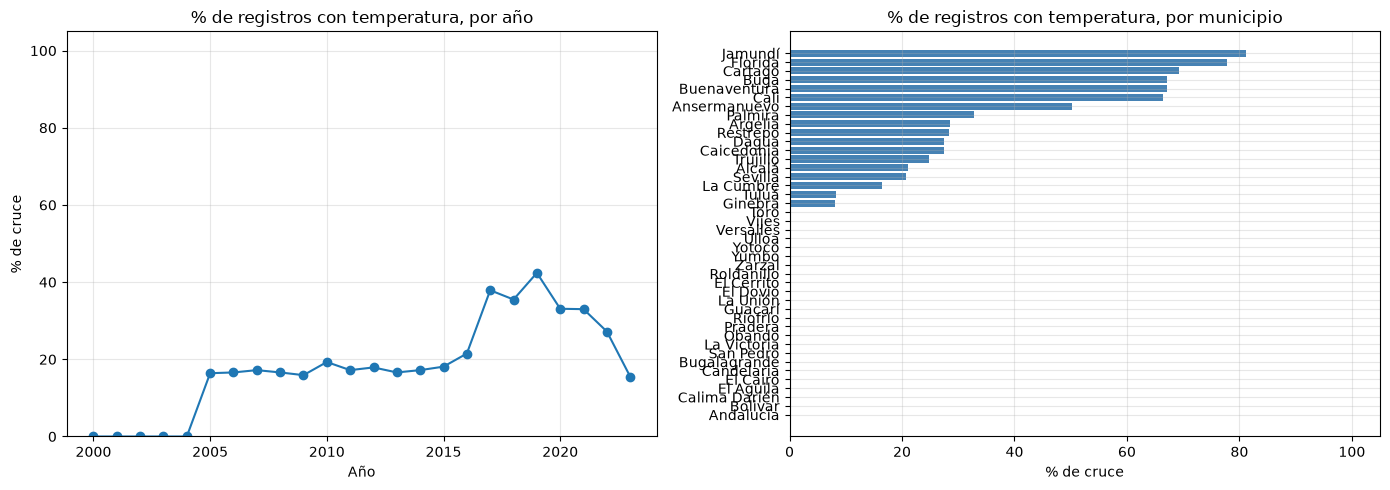

In [92]:
def pct_cruce(df, por):
    g = df.groupby(por).agg(registros=("tiene_temperatura", "size"), con_temperatura=("tiene_temperatura", "sum"))
    g["% cruce"] = (g["con_temperatura"] / g["registros"] * 100).round(1)
    return g

print("Cruce por grupo (solo registros con rendimiento):")
display(pct_cruce(con_rend, "grupo"))
print("Cruce por subregión:")
display(pct_cruce(con_rend, "subregion"))

por_mun = pct_cruce(con_rend, ["id_municipio", "municipio"]).reset_index().sort_values("% cruce")
pares = con_rend[["id_municipio", "anio"]].drop_duplicates()
pares["cruza"] = list(zip(pares["id_municipio"], pares["anio"]))
pares["cruza"] = pares["cruza"].isin(set(zip(temp_anio["id_municipio"], temp_anio["anio"])))
print(f"Pares municipio-año con rendimiento: {len(pares):,} | con temperatura: {int(pares['cruza'].sum()):,} ({pares['cruza'].mean():.1%})")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
por_anio = pct_cruce(con_rend, "anio")["% cruce"]
ejes[0].plot(por_anio.index, por_anio.values, marker="o")
ejes[0].set(title="% de registros con temperatura, por año", xlabel="Año", ylabel="% de cruce", ylim=(0, 105))
ejes[1].barh(por_mun["municipio"], por_mun["% cruce"], color="steelblue")
ejes[1].set(title="% de registros con temperatura, por municipio", xlabel="% de cruce", xlim=(0, 105))
plt.tight_layout()
plt.show()

**Lectura.** Solo cruzó cerca del 18 % de los registros con rendimiento (17 % de los pares municipio-año): la temperatura del IDEAM cubre pocos municipios. La causa principal es estructural, **municipios sin estación** (68 % de lo que no cruzó), seguida de **años anteriores al inicio de las lecturas** (27 %). Por subregión, el cruce es mínimo en el Norte (8,7 %) y alto en el Pacífico (67,2 %, que es un solo municipio). Por eso todo lo que sigue describe los municipios con estación y **no** se puede extrapolar a todo el Valle.

### Reporte de cruce en el formato de la plantilla

In [93]:
cruces = []

def reporte_cruce(tabla, nombre, base):
    conteo = tabla["_merge"].value_counts()
    cruces.append({"cruce": nombre, "registros base": base, "cruzaron": int(conteo.get("both", 0)),
                   "% de cruce": round(conteo.get("both", 0) / base * 100, 2)})
    return tabla

# integ ya no trae la columna _merge (se convirtió en tiene_temperatura); se reconstruye para el reporte
_ = reporte_cruce(integ.assign(_merge=np.where(integ["tiene_temperatura"], "both", "left_only")),
                  "cultivos + temperatura IDEAM (id_municipio + anio)", len(integ))
pd.DataFrame(cruces)

,cruce,registros base,cruzaron,% de cruce
0,cultivos + temperatura IDEAM (id_municipio + anio),31554,5794,18.36


## 5.3 Tabla de linaje de datos (entregable obligatorio)
Entregable exigido por el caso de estudio: de dónde viene cada fuente, hasta qué fecha llega, con qué llave se une y cuánto cruzó.

In [94]:
n_est_total = temp_sin_divipola["codigoestacion"].nunique() + temp["codigoestacion"].nunique()
pct_estaciones = temp["codigoestacion"].nunique() / n_est_total * 100 if n_est_total else np.nan
pct_pares = float(pares["cruza"].mean() * 100)
pct_rend = float(con_rend["tiene_temperatura"].mean() * 100)

entidad_t = meta_temp.get("atribucion") or "IDEAM (Instituto de Hidrología, Meteorología y Estudios Ambientales)"
corte_t = meta_temp.get("fecha_corte_portal") or "No disponible vía API; consultar en la ficha del portal"
licencia_t = meta_temp.get("licencia") or "No disponible vía API; consultar en la ficha del portal"

linaje = pd.DataFrame([
    {"Fuente": "Cultivos del Valle del Cauca (7 conjuntos, Parte 1: cultivos_limpio.csv)",
     "Entidad": "Gobernación del Valle del Cauca",
     "Enlace": "Ver Parte 1 (enlaces de los 7 conjuntos en datos.gov.co)",
     "Fecha de corte": "18 de mayo de 2026 (consolidado de permanentes: 16 de septiembre de 2026)",
     "Llave de cruce": "id_municipio + anio (+ id_cultivo + ciclo)",
     "% de cruce": "100 % (base del análisis)"},
    {"Fuente": f"Temperatura ambiente del aire ({ID_TEMP}), Valle del Cauca, {ANIO_MIN}-{ANIO_MAX}",
     "Entidad": entidad_t,
     "Enlace": f"https://www.datos.gov.co/resource/{ID_TEMP}",
     "Fecha de corte": f"{corte_t} (descarga: {meta_temp.get('fecha_descarga', FECHA_EJECUCION)})",
     "Llave de cruce": "id_municipio (DIVIPOLA derivado del nombre) + anio",
     "% de cruce": f"{pct_rend:.1f} % de los registros con rendimiento ({pct_pares:.1f} % de los pares municipio-año)"},
    {"Fuente": "Catálogo DIVIPOLA (id_municipio ↔ municipio), derivado de cultivos_limpio.csv",
     "Entidad": "DANE (códigos) vía Gobernación del Valle del Cauca",
     "Enlace": "Derivado de cultivos_limpio.csv (DIVIPOLA del DANE)",
     "Fecha de corte": "La de cultivos_limpio.csv",
     "Llave de cruce": "nombre de municipio normalizado → id_municipio",
     "% de cruce": f"{pct_estaciones:.1f} % de las estaciones convertidas a DIVIPOLA"},
])
pd.set_option("display.max_colwidth", 120)
display(linaje)
print("Licencia de la temperatura según el portal:", licencia_t)
print("Origen de la descarga:", origen_temp)

,Fuente,Entidad,Enlace,Fecha de corte,Llave de cruce,% de cruce
0,"Cultivos del Valle del Cauca (7 conjuntos, Parte 1: cultivos_limpio.csv)",Gobernación del Valle del Cauca,Ver Parte 1 (enlaces de los 7 conjuntos en datos.gov.co),18 de mayo de 2026 (consolidado de permanentes: 16 de septiembre de 2026),id_municipio + anio (+ id_cultivo + ciclo),100 % (base del análisis)
1,"Temperatura ambiente del aire (sbwg-7ju4), Valle del Cauca, 2000-2023","Instituto de Hidrología, Meteorología y Estudios Ambientales - IDEAM, Bogotá D.C.",https://www.datos.gov.co/resource/sbwg-7ju4,2026-11-06 (descarga: 2026-11-06),id_municipio (DIVIPOLA derivado del nombre) + anio,18.1 % de los registros con rendimiento (17.0 % de los pares municipio-año)
2,"Catálogo DIVIPOLA (id_municipio ↔ municipio), derivado de cultivos_limpio.csv",DANE (códigos) vía Gobernación del Valle del Cauca,Derivado de cultivos_limpio.csv (DIVIPOLA del DANE),La de cultivos_limpio.csv,nombre de municipio normalizado → id_municipio,100.0 % de las estaciones convertidas a DIVIPOLA


Licencia de la temperatura según el portal: Creative Commons Attribution | Share Alike 4.0 International
Origen de la descarga: API Socrata (datos.gov.co) (caché local)


### Fuentes citadas (enlace y fecha de consulta)
Las normas de entrega exigen citar cada fuente con su enlace y fecha de consulta. La columna *Enlace* de la tabla anterior resume la fuente agrícola con "Ver Parte 1"; aquí se detalla:

| Fuente | Enlace | Fecha de consulta |
|---|---|---|
| Temperatura ambiente del aire (IDEAM), `sbwg-7ju4` | https://www.datos.gov.co/resource/sbwg-7ju4 (ficha: https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Temperatura-Ambiente-del-Aire/sbwg-7ju4/data_preview) | 2026-11-01 (fecha de descarga registrada en la tabla de linaje) |
| Cultivos del Valle del Cauca (7 conjuntos de la Parte 1) |
| Catálogo DIVIPOLA (`id_municipio` ↔ `municipio`) | Derivado de `cultivos_limpio.csv` (códigos DIVIPOLA del DANE) | La de `cultivos_limpio.csv` |


## 5.4 Variables derivadas del rendimiento y base de análisis
- **`rend_relativo`** = rendimiento ÷ mediana del cultivo. El rendimiento de un cultivo se mide en 1 t/ha y el de otro en 60 t/ha; la razón permite compararlos y agruparlos (`1,2` = 20 % por encima de lo típico del cultivo). Solo se calcula con rendimiento **> 0**: los ceros pueden ser pérdida de cosecha o ausencia de dato y no se mezclan en la razón.
- **`rend_anomalia`** = `rend_relativo` menos el promedio de su municipio, cultivo y ciclo. Es el equivalente agrícola de la anomalía térmica: cuánto rindió ese año **frente a lo normal de ese mismo cultivo en ese mismo municipio**. Se calcula con al menos `MIN_ANIOS_ANOMALIA` años.
- **`en_base_analisis`**: registros con temperatura y `rend_relativo` calculable.

In [95]:
valido = integ["tiene_rendimiento"] & (integ["rendimiento_t_ha"] > 0) & (integ["mediana_cultivo"] > 0)
integ["rend_relativo"] = (integ["rendimiento_t_ha"] / integ["mediana_cultivo"]).where(valido)

g = integ.groupby(["id_municipio", "id_cultivo", "ciclo"])["rend_relativo"]
media_hist, n_obs = g.transform("mean"), g.transform("count")
integ["rend_anomalia"] = (integ["rend_relativo"] - media_hist).where(n_obs >= MIN_ANIOS_ANOMALIA)
integ["en_base_analisis"] = integ["tiene_temperatura"] & integ["rend_relativo"].notna()

anotar("T3 Estructurar", "rend_relativo y rend_anomalia", "Columnas convertidas", 2)
base = integ[integ["en_base_analisis"]].copy()
assert len(base) > 0, "No hay registros con temperatura y rendimiento: revisa el cruce"
print(f"Base de análisis: {len(base):,} registros · {base['id_municipio'].nunique()} municipios · "
      f"{base['cultivo'].nunique()} cultivos · años {base['anio'].min()}-{base['anio'].max()}")
ba = base.dropna(subset=["t_anomalia", "rend_anomalia"]).copy()      # base con ambas anomalías (se usa en 6.4 y 7)
print(f"Con anomalías calculables (temperatura y rendimiento): {len(ba):,}")
base.groupby("grupo").agg(registros=("anio", "size"), municipios=("id_municipio", "nunique"), cultivos=("id_cultivo", "nunique"),
                          anio_min=("anio", "min"), anio_max=("anio", "max"))

Base de análisis: 5,593 registros · 18 municipios · 83 cultivos · años 2005-2023
Con anomalías calculables (temperatura y rendimiento): 4,860


,registros,municipios,cultivos,anio_min,anio_max
grupo,,,,,
Permanente,2761,18,47,2005,2023
Transitorio,2832,18,38,2005,2022


---
# 6. Análisis exploratorio sobre el conjunto integrado (RA4)

> Todo lo que sigue es **exploratorio**. Una correlación entre dos variables no demuestra que una cause la otra, y los datos son municipales (no de productores), por lo que pueden esconder la *falacia ecológica*. Por eso el objetivo de esta parte es **formular hipótesis**; ponerlas a prueba es el trabajo de la Parte 3.

> **Tasas por 100.000 habitantes.** El caso de estudio las pide para conteos (accidentes, casos de dengue). Aquí la variable de interés, el **rendimiento (t/ha)**, ya es una tasa normalizada por superficie, así que no se necesita un denominador de población. El denominador de este caso es la **hectárea**.

## 6.1 Descriptivos: tipos de atributo y resumen estadístico
El tipo de atributo decide qué medida tiene sentido (Cap. 3): la moda para nominales, la mediana también para ordinales, y la media solo para intervalo y razón.

| Atributo | Tipo | Discreto / continuo | Medidas válidas |
|---|---|---|---|
| `id_municipio`, `municipio`, `grupo`, `ciclo`, `cultivo` | Nominal | — | Moda, conteos |
| `clima_municipio` (Frío < Templado < Cálido) | Ordinal | — | Moda, mediana |
| `anio`, `mes` | Intervalo | Discreto | Mediana, media |
| `t_media`, `t_anomalia`, `amplitud_termica` (°C) | Intervalo | Continuo | Media, mediana, desviación |
| `rendimiento_t_ha`, `hectareas_sembradas` | Razón | Continuo | Media, mediana, desviación |
| `rend_relativo` | Razón | Continuo | Media, mediana, desviación |
| `n_meses`, `n_estaciones`, `n_lecturas` | Razón | Discreto | Mediana, media |

> Una temperatura de 20 °C **no** es "el doble de calor" que una de 10 °C (la escala Celsius no tiene cero real), pero sí tiene sentido restarlas: por eso la **anomalía** (una diferencia) es una medida válida.

In [96]:
cols_desc = ["rendimiento_t_ha", "rend_relativo", "rend_anomalia", "hectareas_sembradas",
             "t_media", "t_anomalia", "amplitud_termica", "n_meses", "n_estaciones"]
display(base[cols_desc].describe().T.round(3).rename(columns={
    "count": "registros", "mean": "promedio", "std": "desv. estándar",
    "min": "mínimo", "25%": "Q1 (25 %)", "50%": "mediana",
    "75%": "Q3 (75 %)", "max": "máximo"}))
print("Registros por grupo y clase de clima:")
display(pd.crosstab(base["grupo"], base["clima_municipio"], margins=True))

,registros,promedio,desv. estándar,mínimo,Q1 (25 %),mediana,Q3 (75 %),máximo
rendimiento_t_ha,5593.0,14.470,20.464,0.190,4.000,8.680,15.000,150.000
rend_relativo,5593.0,1.092,0.544,0.017,0.778,1.000,1.290,5.000
rend_anomalia,5308.0,0.027,0.433,-1.432,-0.185,-0.005,0.187,3.301
hectareas_sembradas,5593.0,306.593,1644.619,0.000,5.000,15.000,70.000,33900.000
t_media,5593.0,21.396,2.545,11.861,20.348,21.206,23.365,26.256
t_anomalia,5109.0,0.038,1.449,-10.445,-0.388,0.119,0.872,2.937
amplitud_termica,5593.0,2.937,3.118,0.440,1.443,2.039,3.059,22.967
n_meses,5593.0,10.798,1.781,6.000,10.000,12.000,12.000,12.000
n_estaciones,5593.0,1.379,0.716,1.000,1.000,1.000,2.000,4.000


Registros por grupo y clase de clima:


clima_municipio,Cálido,Frío,Templado,All
grupo,,,,
Permanente,1340,481,940,2761
Transitorio,1282,506,1044,2832
All,2622,987,1984,5593


## 6.2 Distribuciones

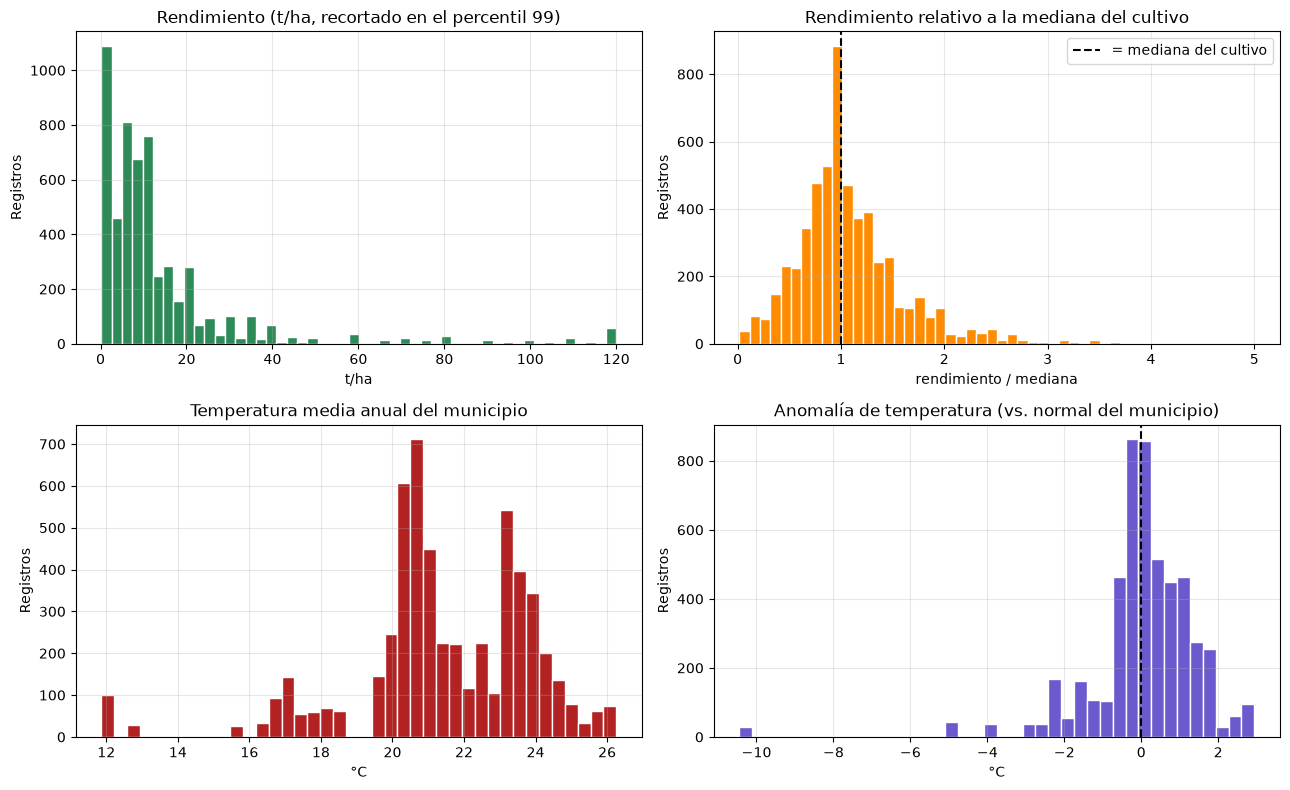

,asimetría,curtosis (en exceso)
rendimiento_t_ha,3.51,14.20
rend_relativo,1.72,6.23
t_media,-1.11,2.35
t_anomalia,-2.55,15.09


In [97]:
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
ejes[0, 0].hist(base["rendimiento_t_ha"].clip(upper=base["rendimiento_t_ha"].quantile(0.99)), bins=50, color="seagreen", edgecolor="white")
ejes[0, 0].set(title="Rendimiento (t/ha, recortado en el percentil 99)", xlabel="t/ha", ylabel="Registros")
ejes[0, 1].hist(base["rend_relativo"].clip(upper=5), bins=50, color="darkorange", edgecolor="white")
ejes[0, 1].axvline(1, color="black", linestyle="--", label="= mediana del cultivo")
ejes[0, 1].set(title="Rendimiento relativo a la mediana del cultivo", xlabel="rendimiento / mediana", ylabel="Registros")
ejes[0, 1].legend()
ejes[1, 0].hist(base["t_media"], bins=40, color="firebrick", edgecolor="white")
ejes[1, 0].set(title="Temperatura media anual del municipio", xlabel="°C", ylabel="Registros")
ejes[1, 1].hist(base["t_anomalia"].dropna(), bins=40, color="slateblue", edgecolor="white")
ejes[1, 1].axvline(0, color="black", linestyle="--")
ejes[1, 1].set(title="Anomalía de temperatura (vs. normal del municipio)", xlabel="°C", ylabel="Registros")
plt.tight_layout()
plt.show()

cols_forma = ["rendimiento_t_ha", "rend_relativo", "t_media", "t_anomalia"]
forma = pd.DataFrame({"asimetría": base[cols_forma].skew(), "curtosis (en exceso)": base[cols_forma].kurtosis()}).round(2)
forma

**Lectura.** El rendimiento tiene una cola derecha larga (asimetría = 3,5: pocos cultivos y municipios rinden mucho más que el resto) y la anomalía térmica una cola izquierda (asimetría = −2,6: algunos años muy fríos para su municipio). `kurtosis()` de pandas es **en exceso** (la normal vale 0): un valor positivo indica colas pesadas, es decir, más atípicos que en una normal. Por eso se usa el **rendimiento relativo** y la correlación de **Spearman** (basada en rangos, robusta a colas y a relaciones no lineales).

### Centro, dispersión, atípicos y normalidad
Se reportan las medidas del Cap. 3 para las variables clave: **media y mediana** (si difieren mucho hay asimetría o atípicos), **desviación estándar e IQR**, y el porcentaje de **atípicos** con la regla del boxplot (fuera de Q1 − 1,5·IQR y Q3 + 1,5·IQR).

Además se contrasta la normalidad con **Shapiro-Wilk** (H0: la variable proviene de una distribución normal; α = 0,05; muestra de hasta 5.000 datos, que es el límite de la prueba). Esto justifica elegir Pearson o Spearman.

In [98]:
vars_resumen = ["rendimiento_t_ha", "rend_relativo", "rend_anomalia", "t_media", "t_anomalia", "amplitud_termica"]

def medidas(s):
    s = s.dropna()
    return pd.Series({"n": len(s), "media": s.mean(), "mediana": s.median(), "moda (a 1 decimal)": s.round(1).mode().iloc[0],
                      "desv. estándar": s.std(), "IQR": s.quantile(0.75) - s.quantile(0.25),
                      "asimetría": s.skew(), "curtosis (exceso)": s.kurtosis(), "% atípicos (1,5·IQR)": pct_atipicos(s)})

display(base[vars_resumen].apply(medidas).T.round(2))

if stats is not None:
    filas = []
    for v in vars_resumen:
        s = base[v].dropna()
        W, p = stats.shapiro(s.sample(min(len(s), 5000), random_state=42))
        filas.append({"variable": v, "W": round(W, 3), "valor p": f"{p:.2g}",
                      "decisión (α = 0,05)": "No se rechaza H0 (compatible con normal)" if p >= 0.05 else "Se rechaza H0 (no es normal)"})
    display(pd.DataFrame(filas).set_index("variable"))
else:
    print("Instala scipy para ejecutar la prueba de Shapiro-Wilk.")

,n,media,mediana,moda (a 1 decimal),desv. estándar,IQR,asimetría,curtosis (exceso),"% atípicos (1,5·IQR)"
rendimiento_t_ha,5593.0,14.47,8.68,10.0,20.46,11.00,3.51,14.20,9.53
rend_relativo,5593.0,1.09,1.00,1.0,0.54,0.51,1.72,6.23,5.17
rend_anomalia,5308.0,0.03,-0.01,0.0,0.43,0.37,1.58,8.15,7.20
t_media,5593.0,21.40,21.21,20.3,2.55,3.02,-1.11,2.35,2.77
t_anomalia,5109.0,0.04,0.12,0.1,1.45,1.26,-2.55,15.09,5.15
amplitud_termica,5593.0,2.94,2.04,1.3,3.12,1.62,4.04,19.06,7.42


,W,valor p,"decisión (α = 0,05)"
variable,,,
rendimiento_t_ha,0.588,5e-76,Se rechaza H0 (no es normal)
rend_relativo,0.893,2.2e-50,Se rechaza H0 (no es normal)
rend_anomalia,0.888,4.5e-51,Se rechaza H0 (no es normal)
t_media,0.918,5.3e-46,Se rechaza H0 (no es normal)
t_anomalia,0.825,4.2e-59,Se rechaza H0 (no es normal)
amplitud_termica,0.539,2.2e-78,Se rechaza H0 (no es normal)


**Lectura.** En las variables de rendimiento la media queda por encima de la mediana (por ejemplo, 14,5 frente a 8,7 t/ha en el rendimiento) y la columna *% atípicos* muestra cuántos valores caen fuera de las barreras del boxplot; con esa asimetría conviene reportar la **mediana**. Con miles de registros Shapiro-Wilk rechaza la normalidad casi siempre (la prueba detecta desviaciones mínimas), y los histogramas confirman colas largas. Por eso las relaciones se miden con **Spearman**, que usa rangos y no exige normalidad. Pearson se reporta solo como referencia.

## 6.3 Tasas por 100 000 habitantes y comparaciones territoriales (*McKinney 5.2 — `sort_values`, `rank`*)

### Sobre las tasas por 100.000 habitantes
El caso de estudio menciona las tasas por 100.000 habitantes para variables de **conteo** (casos, accidentes, contratos), donde se necesita un denominador poblacional para comparar territorios de distinto tamaño. En este proyecto la variable principal es el **rendimiento (t/ha)**, que ya es una **razón** (toneladas producidas por hectárea sembrada): está normalizada por el área, y dividirla por habitantes no tendría sentido agronómico. Para comparar cultivos con escalas distintas se usa además `rend_relativo` (rendimiento ÷ mediana del cultivo) y, para aislar el efecto del clima, las **anomalías** de cada municipio frente a su propio promedio (`t_anomalia`, `rend_anomalia`). Por eso no se incorporó población como fuente de denominador ya que en este estudio es el rendimiento de tonelados sobre hectarea.



### Temperatura por municipio

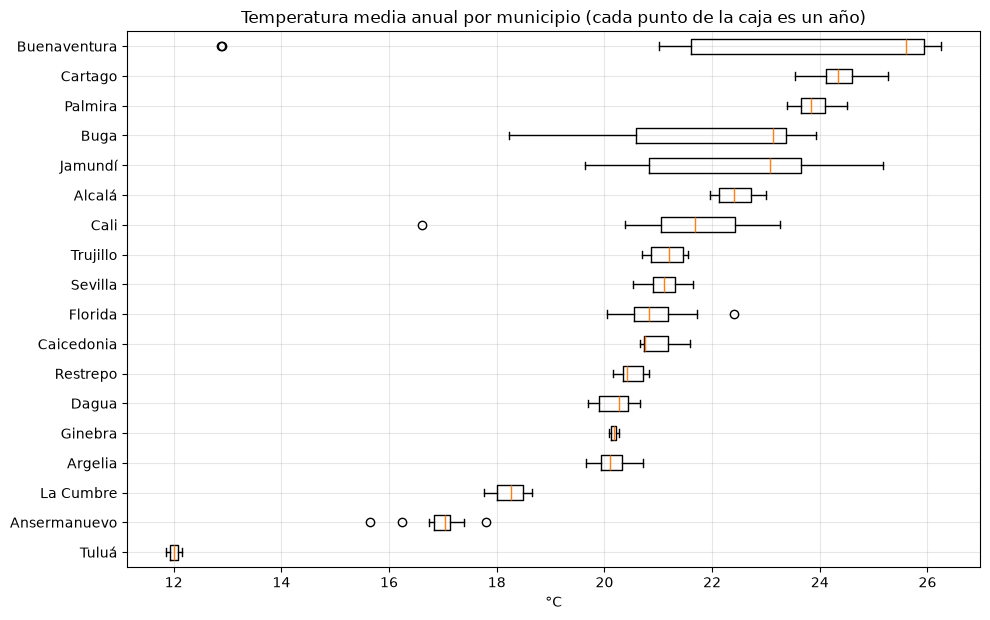

t_media  t_min  t_max  anios  estaciones
subregion municipio                                             
Centro    Tuluá           12.01  11.86  12.16      2           1
Norte     Ansermanuevo    16.93  15.65  17.80     12           1
Sur       La Cumbre       18.23  17.76  18.65      4           1
Norte     Argelia         20.15  19.66  20.71      7           1
Sur       Ginebra         20.17  20.08  20.26      2           1
          Dagua           20.19  19.69  20.66      6           1
Centro    Restrepo        20.49  20.17  20.83      6           1
Sur       Florida         20.93  20.04  22.40     19           2
Centro    Caicedonia      20.98  20.66  21.59      7           1
          Sevilla         21.10  20.53  21.64      4           1
          Trujillo        21.16  20.69  21.56      6           1
Sur       Cali            21.52  16.62  23.27     15           4
Centro    Buga            22.07  18.22  23.93     17           2
Norte     Alcalá          22.45  21.96  23.01      4           1
Sur       Jamundí         22.47  19.64  25.17     19           2
Pacifico  Buenaventura    23.32  12.87  26.26     16           3
Sur       Palmira         23.90  23.39  24.50      8           1
Norte     Cartago         24.36  23.55  25.27     17           1

In [100]:
t_mun = temp_anio.merge(catalogo[["id_municipio", "municipio", "subregion"]], on="id_municipio")
orden = t_mun.groupby("municipio")["t_media"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(orden))))
ax.boxplot([t_mun.loc[t_mun["municipio"] == m, "t_media"] for m in orden], orientation="horizontal", tick_labels=list(orden))
ax.set(title="Temperatura media anual por municipio (cada punto de la caja es un año)", xlabel="°C")
plt.tight_layout()
plt.show()

(t_mun.groupby(["subregion", "municipio"]).agg(t_media=("t_media", "mean"), t_min=("t_media", "min"), t_max=("t_media", "max"),
                                               anios=("anio", "nunique"), estaciones=("n_estaciones", "max"))
 .round(2).sort_values("t_media"))

**Lectura.** Los municipios se ordenan por altitud: Tuluá (12,0 °C) y Ansermanuevo (16,9 °C) son los más fríos y la mayor parte de los registros ronda los 20 a 22 °C (percentil 25 = 20,3 °C y mediana = 21,2 °C). Cada caja resume pocos años (a veces 2 o 4), así que las más estrechas dicen poco sobre la variabilidad real. Tuluá solo tiene 2 años de lectura y una estación, por lo que su valor no es representativo del municipio.

### Mapa de estaciones
No se usan polígonos municipales (evita instalar `geopandas`): se dibujan las estaciones por **longitud y latitud**, coloreadas según su temperatura media. Sirve para ver dónde hay información y dónde no.

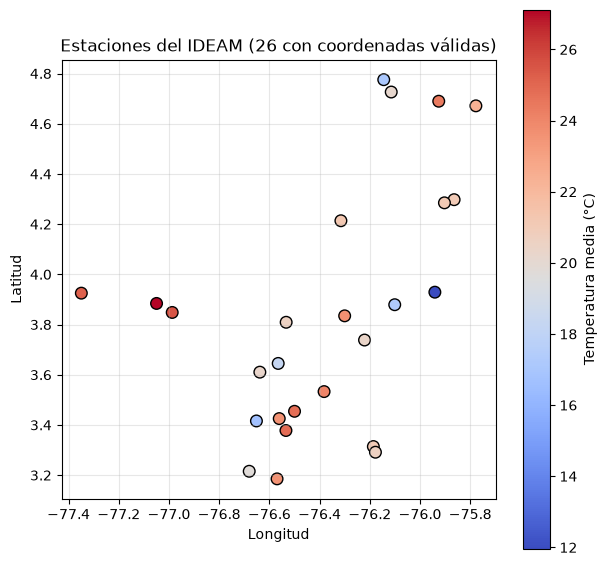

In [101]:
est_t = (temp.groupby("codigoestacion").agg(nombreestacion=("nombreestacion", "first"), latitud=("latitud", "mean"),
                                            longitud=("longitud", "mean"), coord_valida=("coord_valida", "all"),
                                            t_x_n=("t_x_n", "sum"), n=("n_lecturas", "sum")))
est_t["t_media"] = est_t["t_x_n"] / est_t["n"]
mapa = est_t[est_t["coord_valida"]]
if len(mapa):
    fig, ax = plt.subplots(figsize=(7, 7))
    sc = ax.scatter(mapa["longitud"], mapa["latitud"], c=mapa["t_media"], cmap="coolwarm", s=70, edgecolor="black")
    plt.colorbar(sc, ax=ax, label="Temperatura media (°C)")
    ax.set(title=f"Estaciones del IDEAM ({len(mapa)} con coordenadas válidas)", xlabel="Longitud", ylabel="Latitud")
    ax.set_aspect("equal")
    plt.show()
else:
    print("Ninguna estación con coordenadas válidas para el mapa")

**Lectura.** Solo 18 de los 42 municipios agrícolas tienen alguna estación con lecturas válidas, y el mapa deja ver amplias zonas sin cobertura: es coherente con el 17 % de cruce de la sección 5.2.1. La estación **Malpelo – DIMAR** (isla oceánica, 4,096 / −81,609) queda fuera de la caja del Valle y no aparece en el mapa; hoy se marca (`coord_valida`) pero sus lecturas siguen contando en Buenaventura. *Pendiente a decidir:* excluirla, porque una isla a unos 500 km de la costa no representa el clima de las zonas agrícolas del municipio.

### Ranking de municipios (`sort_values`, `rank`)
Posición de cada municipio con estación en temperatura y en rendimiento relativo (1 = el más alto).

In [102]:
rank_mun = (base.groupby("municipio")
            .agg(registros=("anio", "size"), t_media=("t_media", "mean"), rend_relativo=("rend_relativo", "mean")))
rank_mun["rank_temperatura"] = rank_mun["t_media"].rank(ascending=False, method="min").astype(int)
rank_mun["rank_rendimiento"] = rank_mun["rend_relativo"].rank(ascending=False, method="min").astype(int)
rank_mun.sort_values("rank_rendimiento").round(3)

,registros,t_media,rend_relativo,rank_temperatura,rank_rendimiento
municipio,,,,,
Alcalá,96,22.450,1.459,5,1
Florida,731,20.947,1.346,11,2
La Cumbre,123,18.235,1.313,16,3
Ginebra,56,20.171,1.248,14,4
Palmira,341,23.938,1.217,2,5
Dagua,251,20.185,1.195,13,6
Sevilla,109,21.112,1.173,8,7
Restrepo,217,20.502,1.116,12,8
Caicedonia,139,20.951,1.107,10,9


### Comparación territorial (`pivot_table`)

Rendimiento relativo medio por subregión y grupo:


grupo,Permanente,Transitorio,All
subregion,,,
Centro,1.068,1.068,1.068
Norte,1.089,1.043,1.068
Pacifico,0.959,1.094,0.997
Sur,1.139,1.109,1.122
All,1.098,1.087,1.092


Rendimiento relativo medio y temperatura por clima del municipio:


,registros,municipios,t_media,rend_relativo
clima_municipio,,,,
Frío,987,6,17.991,1.106
Templado,1984,6,21.073,1.085
Cálido,2622,6,22.922,1.093


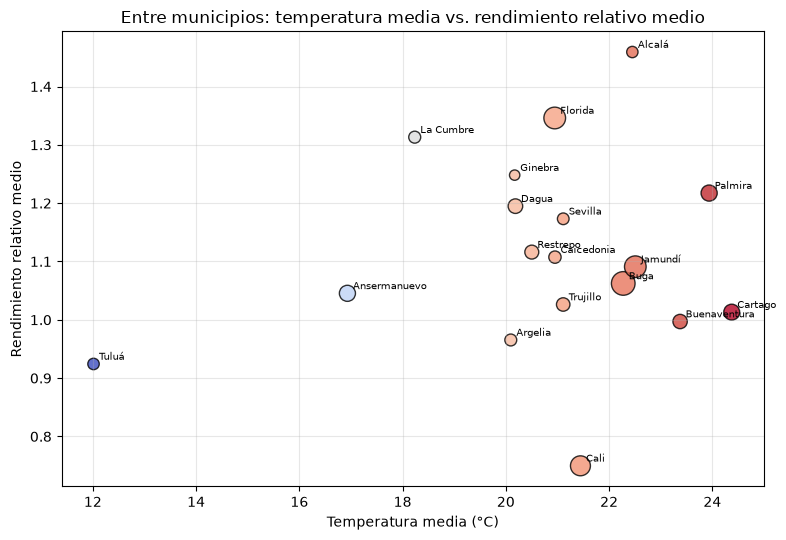

In [103]:
print("Rendimiento relativo medio por subregión y grupo:")
display(pd.pivot_table(base, index="subregion", columns="grupo", values="rend_relativo", aggfunc="mean", margins=True).round(3))

print("Rendimiento relativo medio y temperatura por clima del municipio:")
clima_tab = (base.groupby("clima_municipio").agg(registros=("anio", "size"), municipios=("id_municipio", "nunique"),
                                                 t_media=("t_media", "mean"), rend_relativo=("rend_relativo", "mean"))
             .reindex(["Frío", "Templado", "Cálido"]).round(3))
display(clima_tab)

top = (base.groupby(["id_municipio", "municipio"]).agg(registros=("anio", "size"), t_media=("t_media", "mean"),
                                                       rend_relativo=("rend_relativo", "mean")).reset_index()
       .sort_values("t_media"))
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(top["t_media"], top["rend_relativo"], s=40 + top["registros"] / top["registros"].max() * 250,
                c=top["t_media"], cmap="coolwarm", alpha=0.8, edgecolor="black")
for _, f in top.iterrows():
    ax.annotate(f["municipio"], (f["t_media"], f["rend_relativo"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set(title="Entre municipios: temperatura media vs. rendimiento relativo medio", xlabel="Temperatura media (°C)", ylabel="Rendimiento relativo medio")
plt.tight_layout()
plt.show()

**Lectura.** El rendimiento relativo medio casi no cambia con el clima del municipio (1,106 en frío, 1,085 en templado y 1,093 en cálido): no se ve un patrón por nivel de temperatura. Por subregión, el Sur es el más alto (1,122) y Centro y Norte quedan iguales (1,068). Los permanentes del Pacífico son los más bajos (0,959), pero ese valor viene de un solo municipio.

**Cuidado con esta figura.** Compara **municipios distintos**: un municipio cálido y uno frío difieren en altitud, suelos, cultivos y tecnología, no solo en temperatura. Lo que interesa para la hipótesis es lo que ocurre **dentro de cada municipio** cuando un año resulta más cálido que su normal. Eso es la anomalía.

## 6.4 Correlaciones (*McKinney 5.3 — `corr`, `corrwith`*)
### Matriz de correlación (Spearman)

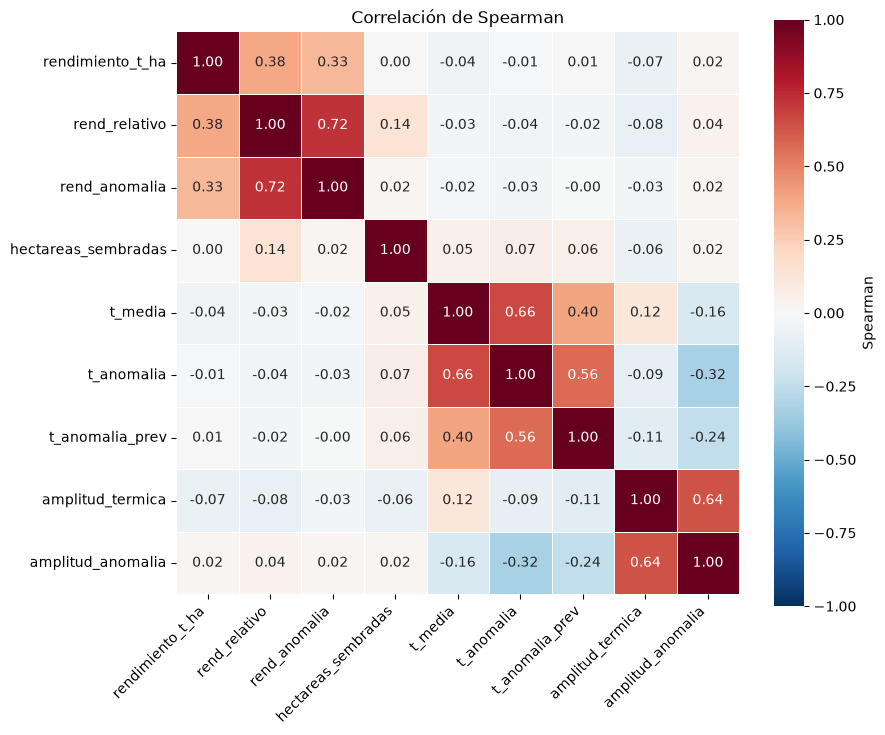

In [104]:
cols_corr = ["rendimiento_t_ha", "rend_relativo", "rend_anomalia", "hectareas_sembradas",
             "t_media", "t_anomalia", "t_anomalia_prev", "amplitud_termica", "amplitud_anomalia"]
cm = base[cols_corr].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"label": "Spearman"}, ax=ax)
ax.grid(False)
ax.set_title("Correlación de Spearman")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Lectura.** La diagonal vale 1 (cada variable consigo misma). `rendimiento_t_ha` y `rend_relativo` correlacionan casi perfecto **por construcción** (el segundo es el primero dividido por una constante por cultivo), y `t_media` con `t_anomalia` o `amplitud_termica` con `amplitud_anomalia` comparten información. Lo que interesa para las hipótesis son las celdas entre `t_anomalia` y `rend_anomalia`, y entre la amplitud y el rendimiento: si están cerca de 0, la relación monótona es débil.

### Temperatura y rendimiento: entre municipios frente a dentro del municipio
Si la relación **entre** municipios (nivel) y la relación **dentro** de cada municipio (anomalía) apuntan en direcciones distintas, es una señal de que la altitud y otros factores están confundiendo el análisis.

,relación,grupo,n,pearson,spearman,p_spearman
0,Nivel: t_media vs. rend_relativo (entre municipios),Todos,5593,-0.009,-0.028,0.036
1,Nivel: t_media vs. rend_relativo (entre municipios),Permanente,2761,0.005,-0.006,0.74
2,Nivel: t_media vs. rend_relativo (entre municipios),Transitorio,2832,-0.022,-0.046,0.014
3,Anomalía: t_anomalia vs. rend_anomalia (dentro del municipio),Todos,4860,-0.020,-0.027,0.064
4,Anomalía: t_anomalia vs. rend_anomalia (dentro del municipio),Permanente,2411,-0.008,-0.022,0.28
5,Anomalía: t_anomalia vs. rend_anomalia (dentro del municipio),Transitorio,2449,-0.033,-0.029,0.15


Lectura: dentro de cada municipio, la relación entre la anomalía térmica y la del rendimiento es prácticamente nula (Spearman = -0.027, n = 4,860). Pearson = -0.02.


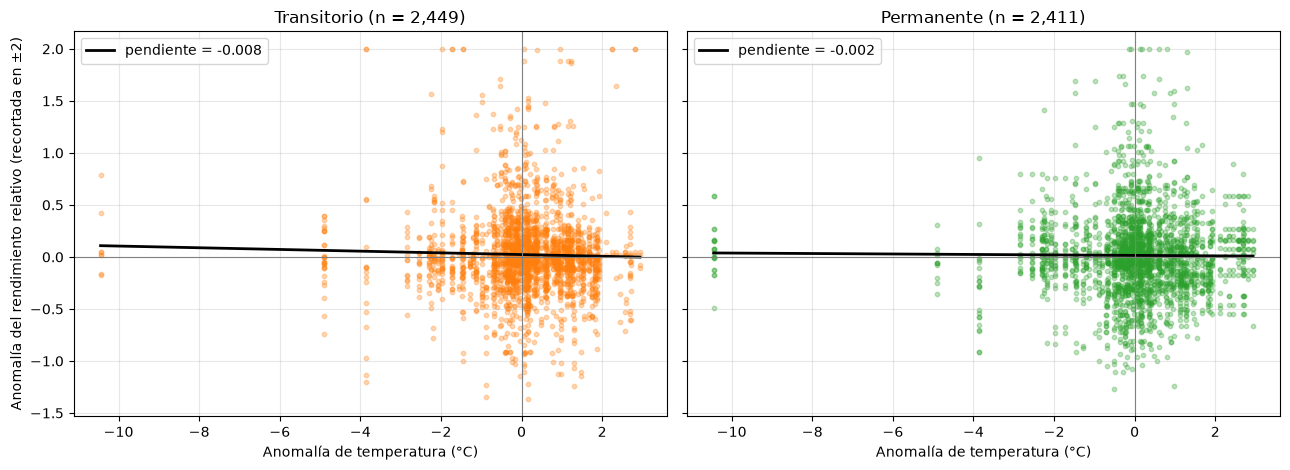

In [105]:
filas = []
for etiqueta, x, y in [("Nivel: t_media vs. rend_relativo (entre municipios)", "t_media", "rend_relativo"),
                       ("Anomalía: t_anomalia vs. rend_anomalia (dentro del municipio)", "t_anomalia", "rend_anomalia")]:
    filas.append({"relación": etiqueta, "grupo": "Todos", **correl(base[x], base[y])})
    for g_, d in base.groupby("grupo"):
        filas.append({"relación": etiqueta, "grupo": g_, **correl(d[x], d[y])})
tabla_corr = pd.DataFrame(filas)
tabla_corr["p_spearman"] = tabla_corr["p_spearman"].map(lambda p: f"{p:.2g}" if pd.notna(p) else "n/d")
display(tabla_corr)

fila = tabla_corr[tabla_corr["relación"].str.startswith("Anomalía") & (tabla_corr["grupo"] == "Todos")].iloc[0]
print(f"Lectura: dentro de cada municipio, la relación entre la anomalía térmica y la del rendimiento es {fuerza(fila['spearman'])} "
      f"(Spearman = {fila['spearman']}, n = {int(fila['n']):,}). Pearson = {fila['pearson']}.")

ba = base.dropna(subset=["t_anomalia", "rend_anomalia"])
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (g_, color) in zip(ejes, [("Transitorio", "tab:orange"), ("Permanente", "tab:green")]):
    d = ba[ba["grupo"] == g_]
    if len(d) < 10:
        ax.set_title(f"{g_}: pocos datos")
        continue
    ax.scatter(d["t_anomalia"], d["rend_anomalia"].clip(-2, 2), s=10, alpha=0.3, color=color)
    pend, ordenada = np.polyfit(d["t_anomalia"], d["rend_anomalia"].clip(-2, 2), 1)
    xs = np.linspace(d["t_anomalia"].min(), d["t_anomalia"].max(), 50)
    ax.plot(xs, pend * xs + ordenada, color="black", linewidth=2, label=f"pendiente = {pend:.3f}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set(title=f"{g_} (n = {len(d):,})", xlabel="Anomalía de temperatura (°C)")
    ax.legend()
ejes[0].set_ylabel("Anomalía del rendimiento relativo (recortada en ±2)")
plt.tight_layout()
plt.show()

### Por cultivo
Se calcula la correlación entre las dos anomalías **para cada cultivo** con suficientes datos. Un efecto promedio puede ocultar cultivos muy sensibles y otros indiferentes.

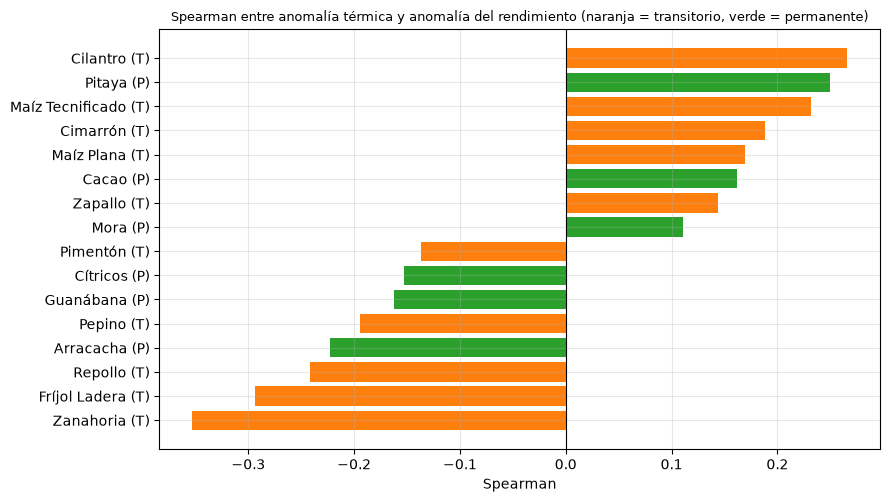

,grupo,cultivo,n,pearson,spearman,p_spearman
27,Transitorio,Cilantro,161,0.137,0.266,0.00064
18,Permanente,Pitaya,36,0.265,0.250,0.14
35,Transitorio,Maíz Tecnificado,89,0.148,0.232,0.029
28,Transitorio,Cimarrón,35,0.041,0.188,0.28
34,Transitorio,Maíz Plana,86,0.094,0.169,0.12
3,Permanente,Cacao,118,0.055,0.162,0.08
45,Transitorio,Zapallo,111,0.103,0.144,0.13
16,Permanente,Mora,102,0.105,0.111,0.27
12,Permanente,Guayaba,123,0.093,0.110,0.23
15,Permanente,Maracuyá,92,0.070,0.105,0.32


Cultivos analizados (≥ 30 observaciones): 46 | con correlación negativa: 23


In [106]:
filas = []
for (g_, cult), d in ba.groupby(["grupo", "cultivo"]):
    if len(d) >= 30:
        filas.append({"grupo": g_, "cultivo": cult, **correl(d["t_anomalia"], d["rend_anomalia"])})
por_cultivo = pd.DataFrame(filas)
if len(por_cultivo):
    por_cultivo = por_cultivo.sort_values("spearman")
    sel = pd.concat([por_cultivo.head(8), por_cultivo.tail(8)]).drop_duplicates()
    colores = sel["grupo"].map({"Transitorio": "tab:orange", "Permanente": "tab:green"})
    fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(sel))))
    ax.barh(sel["cultivo"] + " (" + sel["grupo"].str[0] + ")", sel["spearman"], color=colores)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title="Spearman entre anomalía térmica y anomalía del rendimiento (naranja = transitorio, verde = permanente)",
           xlabel="Spearman")
    ax.title.set_fontsize(9)
    plt.tight_layout()
    plt.show()
    display(por_cultivo.assign(p_spearman=por_cultivo["p_spearman"].map(lambda p: f"{p:.2g}" if pd.notna(p) else "n/d")).tail(10).iloc[::-1])
    print(f"Cultivos analizados (≥ 30 observaciones): {len(por_cultivo)} | con correlación negativa: {int((por_cultivo['spearman'] < 0).sum())}")
else:
    print("Ningún cultivo con 30 o más observaciones con ambas anomalías")

### Por clima del municipio y con rezago de un año

,n,pearson,spearman,p_spearman
clima del municipio,,,,
Frío,654,0.040,0.013,0.743
Templado,1783,-0.002,-0.010,0.679
Cálido,2423,-0.033,-0.037,0.068


,grupo,relación,n,pearson,spearman,p_spearman
0,Permanente,anomalía del año ANTERIOR vs. rend_anomalia,2072,-0.021,-0.013,0.546
1,Transitorio,anomalía del año ANTERIOR vs. rend_anomalia,2117,-0.009,0.009,0.667


registros  rend_anomalia_media
grupo       estado                                    
Permanente  Año frío          527               -0.003
            Año normal       1115                0.034
            Año cálido        769                0.002
Transitorio Año frío          505                0.038
            Año normal       1084                0.040
            Año cálido        860                0.001

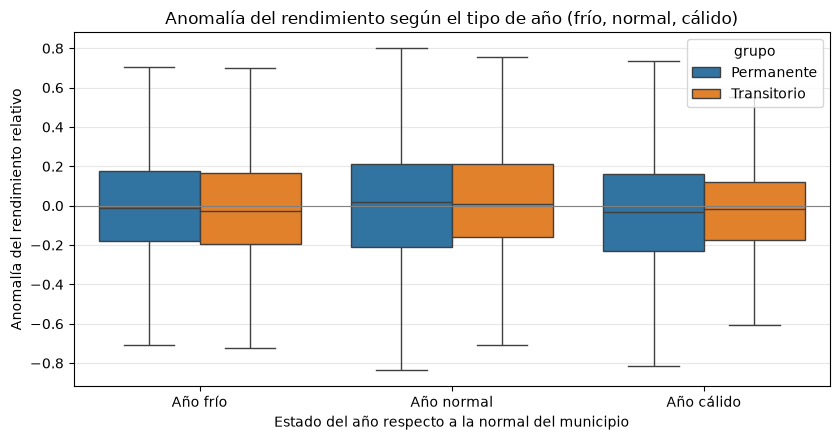

In [107]:
filas = []
for clima, d in ba.groupby("clima_municipio"):
    filas.append({"clima del municipio": clima, **correl(d["t_anomalia"], d["rend_anomalia"])})
display(pd.DataFrame(filas).set_index("clima del municipio").reindex(["Frío", "Templado", "Cálido"]).round(3))

filas = []
for g_, d in base.dropna(subset=["t_anomalia_prev", "rend_anomalia"]).groupby("grupo"):
    filas.append({"grupo": g_, "relación": "anomalía del año ANTERIOR vs. rend_anomalia", **correl(d["t_anomalia_prev"], d["rend_anomalia"])})
display(pd.DataFrame(filas).round(3))

ba2 = ba.assign(estado=pd.cut(ba["t_anomalia"], [-np.inf, -UMBRAL_FRIO_CALIDO, UMBRAL_FRIO_CALIDO, np.inf],
                              labels=["Año frío", "Año normal", "Año cálido"]))
display(ba2.groupby(["grupo", "estado"], observed=True).agg(registros=("anio", "size"), rend_anomalia_media=("rend_anomalia", "mean")).round(3))

orden_estado = ["Año frío", "Año normal", "Año cálido"]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.boxplot(data=ba2, x="estado", y="rend_anomalia", hue="grupo", order=orden_estado, showfliers=False, ax=ax)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(title="Anomalía del rendimiento según el tipo de año (frío, normal, cálido)", xlabel="Estado del año respecto a la normal del municipio",
       ylabel="Anomalía del rendimiento relativo")
plt.tight_layout()
plt.show()


**Qué mirar en estos resultados:**
- Los signos y la **magnitud**: una correlación de −0,05 con miles de registros puede ser estadísticamente significativa y aun así casi irrelevante en la práctica.
- Si **nivel** y **anomalía** coinciden en el signo. Si no, la altitud confunde.
- Si el patrón se repite en **la mayoría de los cultivos** o lo explican uno o dos.

## 6.5 Estacionalidad y tendencia (`resample`, `pivot_table`)

### Estacionalidad y tendencia (series de tiempo con `resample`)
- **Estacionalidad:** cuánto se aparta cada mes de la media anual de su municipio (así se eliminan las diferencias de altitud).
- **Tendencia:** la **anomalía mensual** (el valor del mes menos la media de ese mismo mes en ese municipio) promediada en la región, con `resample("MS")` y una media móvil de 12 meses. Los picos positivos suelen coincidir con episodios de El Niño.

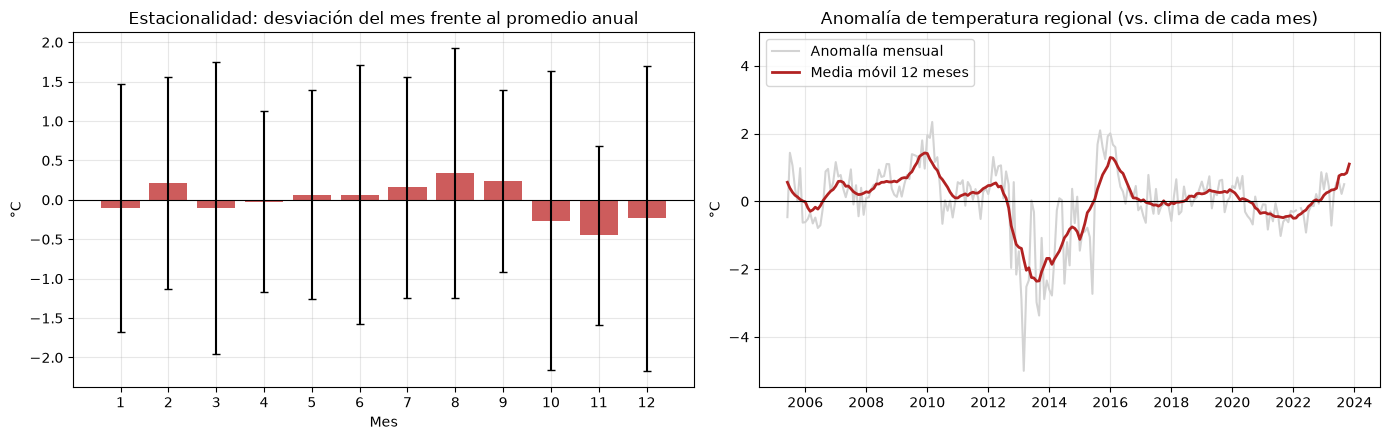

Años más cálidos y más fríos (anomalía regional promedio):


,t_anomalia,municipios
anio,,
2009,0.92,6
2016,0.75,8
2008,0.57,6
2013,-2.25,7
2014,-1.18,7
2021,-0.49,14


In [108]:
tm_ = temp_mes.merge(temp_anio_todo[["id_municipio", "anio", "t_media"]].rename(columns={"t_media": "t_anual"}), on=["id_municipio", "anio"])
estac = tm_.assign(desv_mes=tm_["t_media"] - tm_["t_anual"]).groupby("mes")["desv_mes"].agg(["mean", "std"])

clim = temp_mes.groupby(["id_municipio", "mes"])["t_media"].transform("mean")
temp_mes["anom_mes"] = temp_mes["t_media"] - clim
serie = temp_mes.set_index("fecha")["anom_mes"].resample("MS").mean()
tendencia = serie.rolling(12, min_periods=6, center=True).mean()

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
ejes[0].bar(estac.index, estac["mean"], yerr=estac["std"], color="indianred", capsize=3)
ejes[0].axhline(0, color="black", linewidth=0.8)
ejes[0].set(title="Estacionalidad: desviación del mes frente al promedio anual", xlabel="Mes", ylabel="°C", xticks=range(1, 13))
ejes[1].plot(serie.index, serie.values, color="lightgray", label="Anomalía mensual")
ejes[1].plot(tendencia.index, tendencia.values, color="firebrick", linewidth=2, label="Media móvil 12 meses")
ejes[1].axhline(0, color="black", linewidth=0.8)
ejes[1].set(title="Anomalía de temperatura regional (vs. clima de cada mes)", ylabel="°C")
ejes[1].legend()
plt.tight_layout()
plt.show()

anual = temp_anio.groupby("anio").agg(t_anomalia=("t_anomalia", "mean"), municipios=("id_municipio", "nunique"))
print("Años más cálidos y más fríos (anomalía regional promedio):")
display(pd.concat([anual.nlargest(3, "t_anomalia"), anual.nsmallest(3, "t_anomalia")]).round(2))

**Lectura.** Dos de los tres años más cálidos (2009 y 2016) coinciden con episodios de El Niño (2009-10 y 2015-16), lo esperable; 2008 también sale cálido sin que El Niño lo explique, otra razón para revisar la composición de estaciones. En cambio **2013 (−2,25 °C) y 2014 (−1,18 °C)** son demasiado fríos para un clima tropical, y la anomalía mínima de la base llega a −10 °C. Antes de interpretar el clima conviene revisar si esos valores vienen de **cambios en las estaciones** de un municipio entre años (otra altitud) y no de un enfriamiento real.

#### Diagnóstico de anomalías extremas

In [109]:
ext = (temp_anio.dropna(subset=["t_anomalia"]).assign(abs_anomalia=lambda d: d["t_anomalia"].abs())
       .nlargest(10, "abs_anomalia").merge(catalogo[["id_municipio", "municipio"]], on="id_municipio"))
display(ext[["municipio", "anio", "t_media", "t_media_hist", "t_anomalia", "n_estaciones", "n_meses"]].round(2))
print(f"Anomalías fuera de 1,5·IQR: {pct_atipicos(temp_anio['t_anomalia']):.1f} % de los municipio-año")
print("Anomalías con |valor| > 3 °C:", int((temp_anio['t_anomalia'].abs() > 3).sum()), "municipio-año")

,municipio,anio,t_media,t_media_hist,t_anomalia,n_estaciones,n_meses
0,Buenaventura,2013,12.87,23.32,-10.45,1,12
1,Buenaventura,2014,12.89,23.32,-10.43,2,12
2,Cali,2021,16.62,21.52,-4.90,1,10
3,Buga,2013,18.22,22.07,-3.85,2,12
4,Buenaventura,2016,26.26,23.32,2.94,2,12
5,Jamundí,2021,19.64,22.47,-2.83,2,11
6,Buenaventura,2010,26.14,23.32,2.82,2,11
7,Buenaventura,2017,26.03,23.32,2.72,2,12
8,Buenaventura,2018,26.02,23.32,2.70,2,12
9,Jamundí,2022,25.17,22.47,2.70,1,6


Anomalías fuera de 1,5·IQR: 12.3 % de los municipio-año
Anomalías con |valor| > 3 °C: 4 municipio-año


Si estos casos tienen `n_estaciones` distinto al de los demás años de su municipio, la anomalía mezcla **estaciones** y no solo **años**. La mejora natural, para la Parte 3, es calcular la anomalía **por estación** y luego promediar por municipio.

### Evolución anual del rendimiento y la temperatura

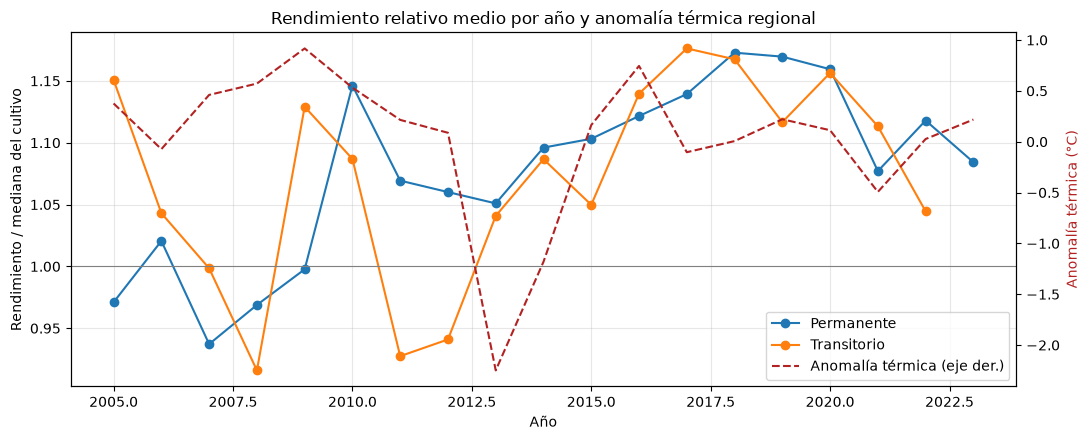

In [110]:
evol = base.groupby(["anio", "grupo"])["rend_relativo"].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4.5))
for g_ in evol.columns:
    ax.plot(evol.index, evol[g_], marker="o", label=g_)
ax2 = ax.twinx()
ax2.plot(anual.index, anual["t_anomalia"], color="firebrick", linestyle="--", label="Anomalía térmica (eje der.)")
ax2.set_ylabel("Anomalía térmica (°C)", color="firebrick")
ax2.grid(False)
ax.axhline(1, color="gray", linewidth=0.8)
ax.set(title="Rendimiento relativo medio por año y anomalía térmica regional", xlabel="Año", ylabel="Rendimiento / mediana del cultivo")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="best")
plt.tight_layout()
plt.show()

**Lectura.** Las líneas continuas muestran el rendimiento relativo medio por grupo (1 = mediana del cultivo) y la punteada, la anomalía térmica regional. Sirve para ver si los años cálidos (2008, 2009, 2016) coinciden con caídas del rendimiento. La comparación es limitada: en años como 2008 y 2009 solo hay 6 municipios con temperatura (frente a 14 en 2021), así que el promedio regional cambia de composición de un año a otro.

---
# 7. Hipótesis para la Parte 3 (entre 3 y 5)

Se formulan cinco (H1 a H5), cada una con H0, Ha, evidencia exploratoria y prueba prevista. Todas usan variables de la integración (`t_anomalia`, `t_anomalia_prev`, `amplitud_anomalia`, `clima_municipio` salen del IDEAM).

## 7.1 Hallazgos formulados como hipótesis para la Parte 3
Cada hipótesis tiene su **evidencia exploratoria** calculada con los datos (no es una prueba: no controla otras variables ni la dependencia entre años de un mismo municipio) y la **prueba prevista** para la Parte 3.

In [111]:
def veredicto(rho, p, esperado):
    # esperado: -1 si se espera correlación negativa, +1 si se espera positiva
    if pd.isna(rho):
        return "Sin datos suficientes"
    if abs(rho) < 0.03:
        return "Asociación prácticamente nula"
    signo_ok = np.sign(rho) == esperado
    sig = (pd.notna(p) and p < 0.05)
    if signo_ok and sig:
        return "Consistente con la hipótesis"
    if signo_ok:
        return "Dirección esperada, sin significancia"
    return "Contraria a la hipótesis" if sig else "Dirección contraria, sin significancia"

H = []
t_all = correl(ba["t_anomalia"], ba["rend_anomalia"])
cal = ba.loc[ba["t_anomalia"] > UMBRAL_FRIO_CALIDO, "rend_anomalia"]
fri = ba.loc[ba["t_anomalia"] < -UMBRAL_FRIO_CALIDO, "rend_anomalia"]
H.append(("H1", "Los años más cálidos que la normal del municipio tienen menor rendimiento relativo.",
          f"rho = {t_all['spearman']}, n = {t_all['n']:,}; años cálidos {cal.mean():+.3f} vs. fríos {fri.mean():+.3f} (rend_anomalia media)",
          veredicto(t_all["spearman"], t_all["p_spearman"], -1),
          "Regresión con efectos fijos por municipio-cultivo (rend_anomalia ~ t_anomalia) y prueba t / Mann-Whitney entre años cálidos y fríos"))

r_t = correl(ba.loc[ba["grupo"] == "Transitorio", "t_anomalia"], ba.loc[ba["grupo"] == "Transitorio", "rend_anomalia"])
r_p = correl(ba.loc[ba["grupo"] == "Permanente", "t_anomalia"], ba.loc[ba["grupo"] == "Permanente", "rend_anomalia"])
mas_fuerte = (pd.notna(r_t["spearman"]) and pd.notna(r_p["spearman"]) and r_t["spearman"] < r_p["spearman"])
H.append(("H2", "La asociación negativa es más fuerte en cultivos transitorios que en permanentes.",
          f"rho transitorios = {r_t['spearman']} (n = {r_t['n']:,}); rho permanentes = {r_p['spearman']} (n = {r_p['n']:,})",
          ("Consistente con la hipótesis" if mas_fuerte and r_t["spearman"] < 0 else "No respaldada por la exploración"),
          "Regresión con interacción t_anomalia × grupo y comparación de pendientes"))

cl = {c: correl(d["t_anomalia"], d["rend_anomalia"]) for c, d in ba.groupby("clima_municipio")}
r_c, r_f = cl.get("Cálido", {}), cl.get("Frío", {})
ok3 = bool(r_c) and bool(r_f) and pd.notna(r_c["spearman"]) and pd.notna(r_f["spearman"]) and r_c["spearman"] < r_f["spearman"]
H.append(("H3", "El efecto de un año cálido es más negativo en municipios cálidos que en municipios fríos.",
          f"rho cálido = {r_c.get('spearman')} (n = {r_c.get('n', 0):,}); rho frío = {r_f.get('spearman')} (n = {r_f.get('n', 0):,})",
          "Consistente con la hipótesis" if ok3 else "No respaldada por la exploración",
          "Modelo con interacción t_anomalia × clima_municipio; gradient boosting con SHAP para ver el efecto por clima"))

pv = base.dropna(subset=["t_anomalia_prev", "rend_anomalia"])
r_prev = correl(pv["t_anomalia_prev"], pv["rend_anomalia"])
pvp = pv[pv["grupo"] == "Permanente"]
r_prev_p = correl(pvp["t_anomalia_prev"], pvp["rend_anomalia"])
H.append(("H4", "La temperatura del año anterior también se asocia con el rendimiento, sobre todo en cultivos permanentes.",
          f"rho (todos) = {r_prev['spearman']}, n = {r_prev['n']:,}; rho permanentes = {r_prev_p['spearman']}, n = {r_prev_p['n']:,}",
          veredicto(r_prev["spearman"], r_prev["p_spearman"], -1),
          "Regresión con t_anomalia y t_anomalia_prev; comparar el aporte del rezago por grupo"))

r_amp = correl(ba["amplitud_anomalia"], ba["rend_anomalia"])
H.append(("H5", "Los años con mayor amplitud térmica (mes más cálido − mes más frío) que la normal rinden menos.",
          f"rho = {r_amp['spearman']}, n = {r_amp['n']:,}",
          veredicto(r_amp["spearman"], r_amp["p_spearman"], -1),
          "Gradient boosting con t_anomalia y amplitud_anomalia; importancia por permutación / SHAP"))

hipotesis = pd.DataFrame(H, columns=["id", "hipótesis", "evidencia exploratoria", "lectura preliminar", "prueba prevista (Parte 3)"])

# H0 y Ha de cada hipótesis (Cap. 3): se fijan antes de la Parte 3, con α = 0,05
FORMAL = {
    "H1": ("No hay relación monótona entre la anomalía térmica y la anomalía del rendimiento (rho = 0).",
           "Hay relación negativa (rho < 0): años más cálidos, menor rendimiento.",
           "spearmanr · mannwhitneyu (años cálidos vs. fríos)"),
    "H2": ("La relación temperatura-rendimiento es igual en transitorios y permanentes.",
           "Es más negativa en transitorios que en permanentes.",
           "Regresión con interacción · mannwhitneyu entre pendientes por municipio-cultivo"),
    "H3": ("El efecto de un año cálido es igual en municipios fríos, templados y cálidos.",
           "El efecto es más negativo en municipios cálidos.",
           "kruskal (3 climas) · modelo con interacción"),
    "H4": ("La anomalía del año anterior no se asocia con el rendimiento (rho = 0).",
           "Se asocia negativamente, con más fuerza en permanentes.",
           "spearmanr con rezago · regresión con t_anomalia y t_anomalia_prev"),
    "H5": ("La amplitud térmica no se asocia con el rendimiento (rho = 0).",
           "Mayor amplitud que la normal se asocia con menor rendimiento.",
           "spearmanr · gradient boosting con SHAP"),
}
hipotesis.insert(2, "H0", hipotesis["id"].map(lambda k: FORMAL[k][0]))
hipotesis.insert(3, "Ha", hipotesis["id"].map(lambda k: FORMAL[k][1]))
hipotesis["prueba SciPy"] = hipotesis["id"].map(lambda k: FORMAL[k][2])
vista = hipotesis.rename(columns={
    "id": "ID",
    "hipótesis": "Hipótesis (lo que se afirma)",
    "H0": "H0: no hay efecto",
    "Ha": "Ha: lo que esperamos",
    "evidencia exploratoria": "Evidencia en los datos (Parte 2)",
    "lectura preliminar": "Lectura preliminar",
    "prueba prevista (Parte 3)": "Cómo se probará en la Parte 3",
    "prueba SciPy": "Prueba estadística (SciPy)",
})[["ID", "Hipótesis (lo que se afirma)", "H0: no hay efecto", "Ha: lo que esperamos",
    "Evidencia en los datos (Parte 2)", "Lectura preliminar",
    "Prueba estadística (SciPy)", "Cómo se probará en la Parte 3"]]

estilo = (vista.style
          .set_properties(**{"text-align": "left", "white-space": "pre-wrap",
                             "vertical-align": "top", "min-width": "170px", "max-width": "260px"})
          .set_table_styles([{"selector": "th", "props": [("text-align", "left"),
                                                          ("background-color", "#f0f2f6"),
                                                          ("color", "#111")]}]))
try:
    estilo = estilo.hide(axis="index")        # pandas >= 1.4
except AttributeError:
    estilo = estilo.hide_index()              # pandas más antiguos
display(estilo)

ID,Hipótesis (lo que se afirma),H0: no hay efecto,Ha: lo que esperamos,Evidencia en los datos (Parte 2),Lectura preliminar,Prueba estadística (SciPy),Cómo se probará en la Parte 3
H1,Los años más cálidos que la normal del municipio tienen menor rendimiento relativo.,No hay relación monótona entre la anomalía térmica y la anomalía del rendimiento (rho = 0).,"Hay relación negativa (rho < 0): años más cálidos, menor rendimiento.","rho = -0.027, n = 4,860; años cálidos +0.001 vs. fríos +0.017 (rend_anomalia media)",Asociación prácticamente nula,spearmanr · mannwhitneyu (años cálidos vs. fríos),Regresión con efectos fijos por municipio-cultivo (rend_anomalia ~ t_anomalia) y prueba t / Mann-Whitney entre años cálidos y fríos
H2,La asociación negativa es más fuerte en cultivos transitorios que en permanentes.,La relación temperatura-rendimiento es igual en transitorios y permanentes.,Es más negativa en transitorios que en permanentes.,"rho transitorios = -0.029 (n = 2,449); rho permanentes = -0.022 (n = 2,411)",Consistente con la hipótesis,Regresión con interacción · mannwhitneyu entre pendientes por municipio-cultivo,Regresión con interacción t_anomalia × grupo y comparación de pendientes
H3,El efecto de un año cálido es más negativo en municipios cálidos que en municipios fríos.,"El efecto de un año cálido es igual en municipios fríos, templados y cálidos.",El efecto es más negativo en municipios cálidos.,"rho cálido = -0.037 (n = 2,423); rho frío = 0.013 (n = 654)",Consistente con la hipótesis,kruskal (3 climas) · modelo con interacción,Modelo con interacción t_anomalia × clima_municipio; gradient boosting con SHAP para ver el efecto por clima
H4,"La temperatura del año anterior también se asocia con el rendimiento, sobre todo en cultivos permanentes.",La anomalía del año anterior no se asocia con el rendimiento (rho = 0).,"Se asocia negativamente, con más fuerza en permanentes.","rho (todos) = -0.002, n = 4,189; rho permanentes = -0.013, n = 2,072",Asociación prácticamente nula,spearmanr con rezago · regresión con t_anomalia y t_anomalia_prev,Regresión con t_anomalia y t_anomalia_prev; comparar el aporte del rezago por grupo
H5,Los años con mayor amplitud térmica (mes más cálido − mes más frío) que la normal rinden menos.,La amplitud térmica no se asocia con el rendimiento (rho = 0).,Mayor amplitud que la normal se asocia con menor rendimiento.,"rho = 0.018, n = 4,860",Asociación prácticamente nula,spearmanr · gradient boosting con SHAP,Gradient boosting con t_anomalia y amplitud_anomalia; importancia por permutación / SHAP


> **Convención (Cap. 3).** Se fija **α = 0,05 antes de mirar los datos**; si p < α se *rechaza H0* y si p ≥ α *no se rechaza H0* (nunca se "acepta" H0: solo se dice que los datos no alcanzan para descartarla). Las hipótesis son **unilaterales** (se espera signo negativo), por eso la prueba debe declararse así en la Parte 3.

> **Importante.** La columna *lectura preliminar* describe lo que se ve en los datos tal como están. Una hipótesis que sale "no respaldada" no es un fracaso: es un resultado. La Parte 3 usará modelos (con control de municipio, cultivo y año) para ponerlas a prueba con rigor y decidir qué se sostiene.

> **Cómo leer la columna *lectura preliminar*.** Es una lectura exploratoria, no una prueba. Para H2 y H3 la etiqueta "Consistente con la hipótesis" solo significa que **el signo o el orden de las correlaciones va en la dirección esperada**; las diferencias son muy pequeñas (por ejemplo, en H2 ρ ≈ −0,029 en transitorios frente a ≈ −0,022 en permanentes) y no se contrastaron formalmente, por lo que **no son concluyentes**. En H1, H4 y H5 la asociación es prácticamente nula (|ρ| < 0,03) y, en H5, el signo es **contrario** al esperado. Que la evidencia exploratoria sea débil no descarta las hipótesis: la Parte 3 las contrastará con modelos que controlan municipio, cultivo y año, y con las pruebas formales indicadas (α = 0,05).


## 7.2 Resumen en el formato de la plantilla

| Hipótesis | Variables (origen) | Viene del gráfico | Cómo se probará en la Parte 3 |
|---|---|---|---|
| **H1.** Los años más cálidos que la normal del municipio tienen menor rendimiento relativo. | `t_anomalia` (IDEAM, integración) y `rend_anomalia` (cultivos) | §6.4: dispersión por grupo y cajas por tipo de año | Regresión con efectos fijos por municipio-cultivo y Mann-Whitney entre años cálidos y fríos; línea base: modelo sin temperatura |
| **H2.** La asociación negativa es más fuerte en transitorios que en permanentes. | `t_anomalia` (IDEAM), `rend_anomalia` y `grupo` (cultivos) | §6.4: dispersión Transitorio frente a Permanente | Regresión con interacción `t_anomalia` × `grupo` y comparación de pendientes |
| **H3.** Un año cálido pesa más en municipios cálidos que en fríos. | `t_anomalia` y `clima_municipio` (IDEAM, derivada) con `rend_anomalia` | §6.4: correlación por clima del municipio | Interacción `t_anomalia` × `clima_municipio` y Kruskal-Wallis |
| **H4.** La temperatura del año anterior también se asocia con el rendimiento, sobre todo en permanentes. | `t_anomalia_prev` (IDEAM, rezago de 1 año) con `rend_anomalia` | §6.4: rezago de un año | Regresión con `t_anomalia` y `t_anomalia_prev`; aporte del rezago por grupo |
| **H5.** Mayor amplitud térmica que la normal se asocia con menor rendimiento. | `amplitud_anomalia` (IDEAM) con `rend_anomalia` | §6.4: matriz de correlación de Spearman | Gradient boosting con `t_anomalia` y `amplitud_anomalia`; importancia por permutación y SHAP |

---
# 8. Guardado, limitaciones y lista de chequeo

## 8.1 Guardar los conjuntos (ETL: Cargar)

Se guardan tres archivos en `data/procesados/` (`utf-8-sig`, para que Excel muestre bien las tildes). Al volver a leerlos hay que usar `dtype={"id_municipio": str, "id_cultivo": str}`.

| Archivo | Contenido |
|---|---|
| `temperatura_municipio_mes.csv` | Temperatura limpia por municipio y mes |
| `temperatura_municipio_anio.csv` | Temperatura limpia por municipio y año, con anomalías |
| `cultivos_temperatura.csv` | **Tabla integrada**: una fila por registro de cultivos con su temperatura. Es la entrada de la Parte 3 |

In [112]:
cols_mes = ["id_municipio", "anio", "mes", "fecha", "t_media", "t_min", "t_max", "n_estaciones", "n_lecturas", "anom_mes"]
temp_mes[cols_mes].to_csv(ARCHIVO_TEMP_MES, index=False, encoding="utf-8-sig")
temp_anio.to_csv(ARCHIVO_TEMP_ANIO, index=False, encoding="utf-8-sig")
integ.to_csv(ARCHIVO_INTEGRADO, index=False, encoding="utf-8-sig")
for ruta in [ARCHIVO_TEMP_MES, ARCHIVO_TEMP_ANIO, ARCHIVO_INTEGRADO]:
    print(f"Guardado: {ruta} ({os.path.getsize(ruta) / 1e6:.2f} MB)")
print(f"\nTabla integrada: {integ.shape[0]:,} filas · {integ.shape[1]} columnas")

Guardado: data/procesados/temperatura_municipio_mes.csv (0.16 MB)
Guardado: data/procesados/temperatura_municipio_anio.csv (0.03 MB)
Guardado: data/procesados/cultivos_temperatura.csv (7.70 MB)

Tabla integrada: 31,554 filas · 38 columnas


In [114]:
# Entregables de la plantilla: linaje y reporte de cruces (CSV) y copia Parquet de las tablas integradas
linaje.to_csv(PROCESSED / "linaje_datos.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(cruces).to_csv(PROCESSED / "reporte_cruces.csv", index=False, encoding="utf-8-sig")
print("Guardado:", PROCESSED / "linaje_datos.csv", "y", PROCESSED / "reporte_cruces.csv")
try:
    integ.to_parquet(PROCESSED / "cultivos_temperatura.parquet", index=False)
    temp_anio.to_parquet(PROCESSED / "temperatura_municipio_anio.parquet", index=False)
    print("Copias Parquet guardadas")
except Exception as e:     # p. ej. falta pyarrow: los CSV de arriba son la entrada oficial de la Parte 3
    print("Parquet omitido:", type(e).__name__, "-", e)

Guardado: data\procesados\linaje_datos.csv y data\procesados\reporte_cruces.csv
Parquet omitido: ImportError - Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip, conda, or your preferred package management tool to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip, conda, or your preferred package management tool to install the fastparquet package.


## 8.2 Validación final
Se valida el **archivo guardado**, no las variables en memoria. Cada `assert` detiene el cuaderno si falla; si la celda termina sin error, todas las pruebas pasaron.

In [115]:
conv = {"id_municipio": str, "id_cultivo": str}
f_int = pd.read_csv(ARCHIVO_INTEGRADO, dtype=conv)
f_ta = pd.read_csv(ARCHIVO_TEMP_ANIO, dtype={"id_municipio": str})
f_tm = pd.read_csv(ARCHIVO_TEMP_MES, dtype={"id_municipio": str})
f_cult = pd.read_csv(ARCHIVO_CULTIVOS, dtype=conv)

# Integridad del merge: no se perdieron ni duplicaron registros agrícolas
assert len(f_int) == len(f_cult), (len(f_int), len(f_cult))
assert not f_int.duplicated(LLAVE_CULTIVO).any(), "Llaves repetidas en la tabla integrada"
assert set(f_cult.columns) <= set(f_int.columns), "Se perdieron columnas de la Parte 1"
assert f_int["id_municipio"].str.fullmatch(r"76\d{3}").all(), "DIVIPOLA inválido"

# Temperatura
assert not f_ta.duplicated(LLAVE_CRUCE).any(), "Temperatura con más de una fila por municipio-año"
assert f_ta["id_municipio"].str.fullmatch(r"76\d{3}").all()
assert f_ta["id_municipio"].isin(catalogo["id_municipio"]).all(), "Temperatura con municipios fuera del catálogo"
assert f_ta["t_media"].between(TEMP_MIN_EXCLUSIVO, TEMP_MAX, inclusive="right").all(), "Temperatura fuera de rango"
assert f_ta["anio"].between(ANIO_MIN, ANIO_MAX).all()
assert (f_ta["n_meses"] >= MIN_MESES_ANIO).all() and (f_ta["n_meses"] <= 12).all()
assert f_tm["mes"].between(1, 12).all()
assert (f_ta["t_min_abs"] <= f_ta["t_media"] + 1e-6).all() and (f_ta["t_media"] <= f_ta["t_max_abs"] + 1e-6).all()

# Cruce coherente
assert (f_int["tiene_temperatura"] == f_int["t_media"].notna()).all(), "tiene_temperatura no coincide con t_media"
assert f_int.loc[f_int["tiene_temperatura"], "t_media"].between(TEMP_MIN_EXCLUSIVO, TEMP_MAX, inclusive="right").all()
assert (f_int["causa_sin_temperatura"].fillna("") != "").eq(~f_int["tiene_temperatura"]).all(), "Causa de no cruce inconsistente"
llaves_t = set(zip(f_ta["id_municipio"], f_ta["anio"]))
assert all((m, a) in llaves_t for m, a in zip(f_int.loc[f_int["tiene_temperatura"], "id_municipio"], f_int.loc[f_int["tiene_temperatura"], "anio"]))

# Anomalías: promedio cero por municipio (por construcción)
med = f_ta.dropna(subset=["t_anomalia"]).groupby("id_municipio")["t_anomalia"].mean().abs().max()
assert med < 1e-6, f"La anomalía no promedia cero por municipio ({med})"
assert (f_int["rend_relativo"].dropna() > 0).all()
assert (f_int["en_base_analisis"] == (f_int["tiene_temperatura"] & f_int["rend_relativo"].notna())).all()
assert set(f_int["clima_municipio"].dropna()) <= {"Frío", "Templado", "Cálido"}

print("Validación final: todas las pruebas pasaron")
pd.Series({"filas integradas": len(f_int), "con temperatura": int(f_int["tiene_temperatura"].sum()),
           "% con temperatura": round(f_int["tiene_temperatura"].mean() * 100, 1),
           "en la base de análisis": int(f_int["en_base_analisis"].sum()),
           "municipios con temperatura": f_ta["id_municipio"].nunique()}, name="resumen")

Validación final: todas las pruebas pasaron


filas integradas              31554.0
con temperatura                5794.0
% con temperatura                18.4
en la base de análisis         5593.0
municipios con temperatura       18.0
Name: resumen, dtype: float64

## 8.3 Reporte de calidad de datos
### Filas antes y después de cada etapa
Las primeras filas están en **lecturas individuales** (el servidor las cuenta antes de agregarlas); las demás, en filas **estación-sensor-mes**, **municipio-año** o **registros de cultivos**.

In [116]:
reporte_filas = pd.DataFrame(LOG_ETAPAS)
reporte_filas["filas_eliminadas"] = reporte_filas["filas_antes"] - reporte_filas["filas_despues"]
reporte_filas

,etapa,filas_antes,filas_despues,decision,filas_eliminadas
0,Servidor: filtro de lecturas válidas (lecturas individuales),5394472,5322499,0 < T ≤ 45 °C; se cuenta antes de descartar,71973
1,Servidor: agregación estación-sensor-año-mes,5322499,2578,"GROUP BY en el servidor: promedio, mínimo, máximo y n de lecturas",5319921
2,Temperatura: copias exactas,2578,2578,drop_duplicates() sobre todas las columnas,0
3,"Temperatura: sin año, mes, temperatura o llave",2578,2578,dropna() sobre las columnas indispensables,0
4,Temperatura: valores fuera de rango o incoherentes,2578,2578,Reglas de rango y coherencia mínima ≤ media ≤ máxima,0
5,Temperatura: unidad distinta de °C,2578,2578,Se excluyen unidades que no son grados Celsius,0
6,Temperatura: sensores de máxima o mínima,2578,2578,Se conservan ['Media/Instantánea'],0
7,Temperatura: consolidar llave estación-sensor-mes,2578,2578,groupby + media ponderada por n de lecturas,0
8,Temperatura: meses con pocas lecturas,2578,2499,n_lecturas ≥ 30 por estación-sensor-mes,79
9,Temperatura: municipio sin código DIVIPOLA,2499,2499,"Nombre no resuelto por exacto, alias ni aproximado",0


### Porcentaje de nulos por columna
Se compara la temperatura **tal como llegó** (agregada del servidor) con la tabla final, y se muestran los nulos de las columnas que el cruce añadió a los cultivos.

In [117]:
filas_nulos = []
for col, final in [("municipio", None), ("latitud", None), ("longitud", None), ("unidadmedida", None), ("t_media", "t_media")]:
    antes = round(float(crudos_temp_arm[col].isna().mean() * 100), 2)
    despues = round(float(temp_anio[final].isna().mean() * 100), 2) if final else "(se resuelve a id_municipio)" if col == "municipio" else "—"
    filas_nulos.append((col, "temperatura IDEAM (agregada)", antes, despues))
display(pd.DataFrame(filas_nulos, columns=["columna", "conjunto", "pct_nulos_antes", "pct_nulos_despues"]))

print("Nulos en las columnas que aporta el cruce (sobre la tabla integrada):")
(f_int[["t_media", "t_anomalia", "t_anomalia_prev", "amplitud_termica", "clima_municipio", "rend_relativo", "rend_anomalia"]]
 .isna().mean().mul(100).round(2).rename("pct_nulos").to_frame())

,columna,conjunto,pct_nulos_antes,pct_nulos_despues
0,municipio,temperatura IDEAM (agregada),0.0,(se resuelve a id_municipio)
1,latitud,temperatura IDEAM (agregada),0.0,—
2,longitud,temperatura IDEAM (agregada),0.0,—
3,unidadmedida,temperatura IDEAM (agregada),0.0,—
4,t_media,temperatura IDEAM (agregada),0.0,0.0


Nulos en las columnas que aporta el cruce (sobre la tabla integrada):


,pct_nulos
t_media,81.64
t_anomalia,83.20
t_anomalia_prev,85.52
amplitud_termica,81.64
clima_municipio,81.64
rend_relativo,1.98
rend_anomalia,6.86


### Resumen y registro de cambios
Los *registros marcados* no se eliminan: llevan una bandera (`tiene_temperatura`, `en_base_analisis`, `causa_sin_temperatura`, `coord_valida`) para que el análisis decida.

In [118]:
registro = pd.DataFrame(CAMBIOS)
display(registro.groupby("tipo", sort=False)["cantidad"].sum().to_frame("cantidad"))
registro

,cantidad
tipo,
Lecturas descartadas en el servidor,71973
Filas eliminadas,110
Columnas eliminadas,0
Valores corregidos,3448
Columnas convertidas,15
Registros marcados,1


,etapa,operacion,tipo,cantidad,detalle
0,Extraer,Lecturas con 0 °C descartadas en el servidor,Lecturas descartadas en el servidor,71881,
1,Extraer,Lecturas fuera de rango descartadas en el servidor,Lecturas descartadas en el servidor,92,
2,T1 Eliminar,Temperatura: copias exactas,Filas eliminadas,0,
3,T1 Eliminar,Temperatura: columnas vacías,Columnas eliminadas,0,
4,T2 Corregir,TRIM: espacios en extremos y dobles internos,Valores corregidos,870,
5,T2 Corregir,Marcadores de faltante convertidos a NaN,Valores corregidos,0,
6,T2 Corregir,"upper(): departamento, municipio, estación, sensor y unidad",Valores corregidos,2578,
7,T3 Estructurar,"Texto a número (temperatura, coordenadas, año, mes)",Columnas convertidas,8,
8,T3 Estructurar,"Filas sin año, mes, temperatura o llave",Filas eliminadas,0,
9,T3 Estructurar,Filas fuera de rango o incoherentes,Filas eliminadas,0,


### Funciones de Pandas evidenciadas

| Función | Dónde se usa |
|---|---|
| `astype` | T3.1 (año, mes y lecturas a entero); T3.9 (clima como texto) |
| `to_datetime` | T3.8 (`fecha` desde año y mes) |
| Métodos `str` | T2 (`strip`, `replace`, `upper`), T3.4 (`contains` por regex), T3.7 (nombres) |
| `groupby` con `agg` | T3.5, T3.8, T3.9 (consolidar y subir de nivel), 5.2.1, 6.x |
| `pivot_table` | 6.3 (rendimiento por subregión y grupo) |
| `resample` | 6.5 (anomalía térmica mensual de la región) |
| `merge` | T3.7 (nombre → DIVIPOLA), 5.2 (cultivos + temperatura, `left`, `many_to_one`), T3.9 (rezago) |
| `reindex` | 5.1 (malla municipio-año con `fill_value=0`) |
| `rank`, `sort_values` | 6.3 (ranking de municipios) |


## 8.4 Limitaciones

### Limitaciones del análisis exploratorio
- **Cobertura:** solo hay temperatura en los municipios con estación y en los años con lecturas suficientes; se mide en la sección 5.2.1.
- **Una estación no es un municipio:** la temperatura de la estación puede no representar las zonas agrícolas, que suelen estar a otra altitud.
- **Solo temperatura:** el rendimiento también depende de lluvia, plagas, precios, tecnología y riego, que no están en el modelo.
- **Falacia ecológica:** los datos son municipales; no se puede concluir sobre fincas individuales.
- **Dependencia entre observaciones:** varios registros comparten municipio y año (la misma temperatura para todos los cultivos). Los valores p son orientativos.

---
## Decisiones y justificación

| Hallazgo | Decisión | Justificación |
|---|---|---|
| 93,5 millones de lecturas a nivel nacional | Filtrar departamento y periodo, y **agregar por estación-sensor-mes en el servidor** | Evita descargar y procesar millones de filas; la agricultura es anual |
| Lecturas de 0 °C y valores > 45 °C | Descartarlas en el servidor, **contándolas antes** | 0 °C es falla de sensor, no clima del Valle; el conteo queda en el reporte |
| Sensores de temperatura máxima y mínima | Excluirlos de la media | Son magnitudes distintas; promediarlas con la media sesga el resultado |
| Unidad distinta de °C | Excluir | Mezclar escalas distorsiona el promedio |
| Estación-sensor-mes repetido | Consolidar con **media ponderada por lecturas** | Promediar promedios sin peso daría el mismo peso a un mes con 40 lecturas y a uno con 4.000 |
| Mes con menos de `MIN_LECTURAS_MES` lecturas | Excluir | Un promedio de pocas lecturas no representa el mes |
| Año con menos de `MIN_MESES_ANIO` meses | Excluir el municipio-año | Un promedio de pocos meses queda sesgado por estacionalidad |
| IDEAM sin DIVIPOLA | Catálogo + alias + nombre aproximado (revisable) | Es la única llave disponible; lo no resuelto no se cruza y se documenta |
| Municipios sin estación | **No imputar** con vecinos | La temperatura cambia con la altitud en pocos kilómetros |
| Correlación entre municipios mezcla altitud, suelo y tecnología | Usar **anomalías** respecto al promedio de cada municipio | Aísla el efecto de que un año sea más cálido de lo normal |
| Rendimientos en escalas distintas por cultivo | `rend_relativo` = rendimiento ÷ mediana del cultivo | Permite comparar y agrupar cultivos |
| Cola larga en el rendimiento | Spearman en lugar de solo Pearson | Es robusta a asimetrías y relaciones no lineales |
| Registros con rendimiento 0 | Excluirlos de `rend_relativo` | Pueden ser pérdida de cosecha o ausencia de dato; no se mezclan en una razón |

## Limitaciones conocidas
- **Cobertura espacial y temporal limitada:** hay municipios sin estación y estaciones que empezaron a operar tarde.
- **Una estación por municipio no refleja zonas agrícolas** a distinta altitud.
- **Correlación no es causalidad:** quedan por controlar lluvia, riego, plagas, tecnología y precios.
- **Falacia ecológica:** el análisis es municipal.
- **Nombres aproximados:** la coincidencia por similitud puede errar; la tabla de T3.7 debe revisarse.
- **Cambio de estaciones entre años:** la temperatura municipal promedia las estaciones activas cada año; si cambia el conjunto de estaciones (otra altitud), la anomalía mezcla estaciones y clima. Mejora prevista: anomalía por estación.
- **Estación oceánica de Malpelo:** sigue contando en Buenaventura aunque no representa sus zonas agrícolas (ver mapa de 6.3).
- **Periodos distintos en la agricultura:** transitorios hasta 2022 y permanentes hasta 2023 (heredado de la Parte 1).

## Conclusiones
1. Integrar fuentes obliga a **igualar granularidad** antes de unir: millones de lecturas se convirtieron en un dato por municipio-año.
2. Cuando falta la llave, **se construye y se mide**: el nombre del IDEAM se convirtió en DIVIPOLA y se reportó cuánto no se pudo.
3. Un cruce nunca es del 100 %: lo importante es **medirlo y explicar cada causa** de no cruce.
4. Comparar un municipio **consigo mismo** (anomalías) evita confundir el clima con la altitud.
5. No todo faltante se imputa: la ausencia de estación es información.
6. El análisis exploratorio **produce hipótesis, no conclusiones**: cinco quedan listas para ponerse a prueba en la Parte 3.
7. Validar sobre el archivo guardado con `assert` hace la calidad comprobable.

**Salida de la Parte 2:** `data/procesados/cultivos_temperatura.csv`, con 5 hipótesis (H1-H5), lista para la Parte 3 (modelos de aprendizaje automático y comunicación de resultados).

### Lista de chequeo (rúbrica RA3 y RA4)

- [x] Al menos una fuente externa por API o base de datos externa (IDEAM por API Socrata). **Falta la segunda fuente para el nivel excelente** (ver 3.1)
- [x] Tabla de linaje: fuente, entidad, fecha de corte, llave y % de cruce (§5.3)
- [x] Armonización documentada: llaves, unidades, granularidad, codificación (§4)
- [x] % de cruce **y sus causas** (§5.2.1)
- [ ] Tasas normalizadas y gráficos con conclusión en el título: el rendimiento ya está normalizado por hectárea (§6.3), pero los títulos de los gráficos son descriptivos y no enuncian la conclusión
- [x] Entre 3 y 5 hipótesis verificables, con variables de la integración (§7)
- [ ] El cuaderno corre de principio a fin, sin datos pesados en el repositorio: verificar con *Kernel → Restart & Run All*
- [ ] Fuentes citadas con enlace y fecha de consulta: falta pegar los 7 enlaces de la Parte 1 en la celda de "Fuentes citadas" (§5.3)